# Анализ TCR (TRB) для наивных CD4 T-клеток (nCD4)

Копия семинарского ноутбука `UCB_seminar.ipynb`, в которой анализ повторён на популяции nCD4 вместо nTreg.

## Imports

**Назначение библиотек.** `pandas` — таблицы и метаданные; `os`/`pathlib` — пути; `repseq.clonosets` — поиск таблиц клонотипов; `repseq.clone_filter` — фильтрация; `repseq.stats` — вычисление метрик; `repseq.plot` — построение графиков; `repseq.beta` — сравнение образцов; `repseq.clustering` — поиск близких последовательностей. `CategoricalDtype` задаёт порядок групп на графиках.

In [1]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

**Относительные пути.** Ноутбук ищет корень проекта по наличию `environment.yml` и папки `notebooks`, поэтому не требует фиксированного домашнего каталога пользователя. Для корректной работы открывайте его из проекта или любой его вложенной папки. `WORKING_DIR` — место для **новых результатов**, а не для входных FASTQ/клоносетов.

## WORKING DIR

In [2]:
# Ищем корень проекта автоматически; затем задаём каталог для результатов repseq.
from pathlib import Path

# Portable to any unpacked ImmuneSem location.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = str(PROJECT_ROOT / "outputs" / "repseq")


In [3]:
# Создаём outputs/repseq при первом запуске, если такой папки ещё нет.
os.makedirs(WORKING_DIR, exist_ok=True)

**Что представляет собой входной датасет.** Здесь используются уже обработанные данные RepSeq: файлы `*.clonotypes.TRB.txt` с клонотипами, а не исходные FASTQ. В исходной схеме подготовки данных MiGEC учитывал UMI, затем MiXCR собирал клонотипы. Поэтому счётчики с историческим названием *reads* в этих таблицах отражают результаты обработки на уровне молекулярных наблюдений, а не просто число исходных FASTQ-прочтений.

Обратите внимание на различие: **число клонотипов** — сколько различных последовательностей обнаружено; **число наблюдений** — сколько раз эти последовательности зарегистрированы. Именно второе используется при анализе частот и даунсэмплировании.

## Read clonosets

In [4]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")


In [5]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False, 
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,c4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
1,UCB5_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
2,a12_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
3,o1_nTreg_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
4,o4_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
...,...,...,...
82,UCB1_nCD8_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
83,UCB6_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
84,o7_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...
85,UCB9_nCD8_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...


The dataset also contains metadata table, which can read as a pandas DataFrame

**Метаданные связывают образцы с экспериментом.** `sample_id` — имя образца и ключ объединения; `experimental_group` — возрастная/экспериментальная группа; `donor_id` — донор; `subset` — отсортированная клеточная популяция. Для групп `preterm`, `term`, `late` источник обозначается как UCB (пуповинная кровь), для остальных — PB (периферическая кровь).

Заданный порядок категорий нужен для осмысленного расположения групп на графиках; это **не** числовая переменная и **не** результат статистического теста. Проверяйте количество образцов в каждой группе, прежде чем сравнивать её с другими.

## Create metadata

In [6]:
# Задаём порядок экспериментальных групп и клеточных популяций для графиков.
# # Затем читаем метаданные и добавляем источник материала: UCB или PB.
# Define the custom ordered type
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
# metadata["sample_id"] = metadata["sample_id"].apply(lambda x: x.split("_TRB")[0])
metadata.tail()

,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


**Почему выделяем одну популяцию.** В датасете есть несколько отсортированных популяций (nCD4, nTreg, nCD8); их репертуары различаются и по биологии, и по глубине секвенирования. На семинаре анализировали `nTreg`, в этом ноутбуке - **`nCD4`** (наивные CD4 T-хелперы), чтобы сравнение возрастных групп не смешивалось с различиями клеточных типов.

## Subset clonosets

In [7]:
# Объединяем пути к клоносетам с метаданными и оставляем популяцию nCD4.
clonosets_cd4 = clonosets.merge(metadata).query("subset == 'nCD4'").reset_index(drop=True)
clonosets_cd4

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,o3_mnCD4_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,older_adults,o3,nCD4,PB
1,o5_mnCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,older_adults,o5,nCD4,PB
2,UCB5_nCD4_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB5,nCD4,UCB
3,a11_mnCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,adults,a11,nCD4,PB
4,UCB2_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,term,UCB2,nCD4,UCB
5,UCB4_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB4,nCD4,UCB
6,c1_mnCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,children,c1,nCD4,PB
7,a9_mnCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,adults,a9,nCD4,PB
8,UCB3_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,term,UCB3,nCD4,UCB
9,a5_mnCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,adults,a5,nCD4,PB


In [8]:
# Сколько образцов nCD4 попало в каждую группу.
clonosets_cd4.groupby("experimental_group", observed=False).size().rename("samples").to_frame()

,samples
experimental_group,
preterm,3
term,6
late,4
children,4
adults,9
older_adults,4


In [9]:
# Проверяем схему сортировки: часть образцов называется mnCD4, а не nCD4.
# Показываем те колонки исходной таблицы метаданных, которые описывают сортировку (если они есть).
metadata_raw = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))
sort_cols = [c for c in ["sorting_subtype", "gating_strategy"] if c in metadata_raw.columns]
print("Колонки метаданных:", list(metadata_raw.columns))
metadata_raw.query("subset == 'nCD4'").groupby(["experimental_group"] + sort_cols).size().rename("samples").to_frame()

Колонки метаданных: ['sample_id', 'chain', 'filename', 'experimental_group', 'donor_id', 'subset', 'tissue', 'sex', 'age', 'gestational_age', 'replicate', 'family', 'clonotypes', 'clonotypes_functional', 'UMI', 'UMI_functional', 'sorting_subtype', 'gating_strategy']


samples
experimental_group sorting_subtype gating_strategy                        
adults             mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        9
children           mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        4
late               nCD4            CD3+CD4+                              4
older_adults       mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        4
preterm            nCD4            CD3+CD4+                              3
term               mnCD4           CD3+CD4+CD25-CD45RA+CD27+CD31-        2
                   nCD4            CD3+CD4+                              4

**Состав выборки nCD4.** В имени части образцов стоит `mnCD4`, а не `nCD4`: это все образцы периферической крови (children, adults, older_adults) и часть образцов пуповинной крови. Схема сортировки у них могла отличаться (см. таблицу выше), поэтому различия между UCB и PB могут частично отражать различия сортировки, а не только возраст.

**Сначала оценим объём и качество.** В `clonoset_stats` важно различать `clones` и `clones_func` (общее число клонотипов и продуктивных), `reads` и `reads_func` (число наблюдений), а также `clones_nonfunc` и синглтоны.

**Важное свойство конкретного набора:** в сохранённой таблице статистики колонки `umi`, `umi_func` и т. п. имеют значения `NaN`. Поэтому некоторые функции `repseq` выдают предупреждение и **используют `reads` вместо отдельного столбца UMI**. В этих исторически обработанных MiGEC/MiXCR-данных не следует автоматически отождествлять `reads` с сырыми ридами FASTQ. Это важно для объяснения `by_umi=True` ниже.

## Have a look at clonosets contents

In [10]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_cd4 = stats.calc_clonoset_stats(clonosets_cd4, cpu=2)
clonoset_stats_cd4

Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,o3_mnCD4_TRB_2,TRB,85870,81362,35233,46129,4508,0.052498,203771,198048,5723,0.028085,NaN,NaN,NaN,NaN,NaN
1,o5_mnCD4_TRB_1,TRB,19077,17835,9580,8255,1242,0.065105,37447,35797,1650,0.044062,NaN,NaN,NaN,NaN,NaN
2,UCB5_nCD4_TRB_2,TRB,49366,46447,21731,24716,2919,0.059130,104347,100848,3499,0.033532,NaN,NaN,NaN,NaN,NaN
3,a11_mnCD4_TRB_1,TRB,27477,26285,16492,9793,1192,0.043382,43923,42563,1360,0.030963,NaN,NaN,NaN,NaN,NaN
4,UCB2_nCD4_TRB_1,TRB,81956,78511,44542,33969,3445,0.042035,139476,135541,3935,0.028213,NaN,NaN,NaN,NaN,NaN
5,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
6,c1_mnCD4_TRB_1,TRB,34691,33429,25394,8035,1262,0.036378,45792,44444,1348,0.029437,NaN,NaN,NaN,NaN,NaN
7,a9_mnCD4_TRB_1,TRB,24536,23743,16874,6869,793,0.032320,36490,35572,918,0.025158,NaN,NaN,NaN,NaN,NaN
8,UCB3_nCD4_TRB_1,TRB,38736,36701,25164,11537,2035,0.052535,55515,53298,2217,0.039935,NaN,NaN,NaN,NaN,NaN
9,a5_mnCD4_TRB_1,TRB,52283,48869,21910,26959,3414,0.065298,118837,114159,4678,0.039365,NaN,NaN,NaN,NaN,NaN


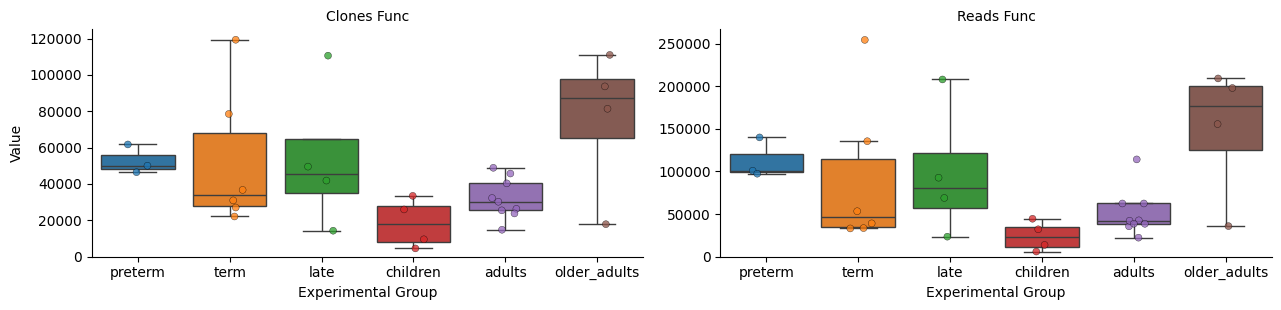

In [11]:
# Сравниваем объём функциональной части репертуаров между экспериментальными группами.
rsplot.clonoset_stats(clonoset_stats_cd4, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [12]:
# Сортируем образцы по числу функциональных наблюдений: это помогает выбрать downsample.
clonoset_stats_cd4.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
13,c2_mnCD4_TRB_1,TRB,4667,4508,3481,1027,159,0.034069,6084,5912,172,0.028271,NaN,NaN,NaN,NaN,NaN
12,c4_mnCD4_TRB_1,TRB,9912,9515,6818,2697,397,0.040052,14155,13695,460,0.032497,NaN,NaN,NaN,NaN,NaN
26,a7_mnCD4_TRB_1,TRB,15395,14760,10071,4689,635,0.041247,22940,22220,720,0.031386,NaN,NaN,NaN,NaN,NaN
5,UCB4_nCD4_TRB_1,TRB,15004,14235,8453,5782,769,0.051253,24297,23395,902,0.037124,NaN,NaN,NaN,NaN,NaN
22,c5_mnCD4_TRB_1,TRB,26673,25952,21374,4578,721,0.027031,32840,32077,763,0.023234,NaN,NaN,NaN,NaN,NaN
29,UCB6_nCD4_TRB_1,TRB,23056,22069,14572,7497,987,0.042809,34149,33053,1096,0.032095,NaN,NaN,NaN,NaN,NaN
25,UCB12_mnCD4_TRB_1,TRB,28150,27005,22218,4787,1145,0.040675,34663,33459,1204,0.034734,NaN,NaN,NaN,NaN,NaN
7,a9_mnCD4_TRB_1,TRB,24536,23743,16874,6869,793,0.032320,36490,35572,918,0.025158,NaN,NaN,NaN,NaN,NaN
1,o5_mnCD4_TRB_1,TRB,19077,17835,9580,8255,1242,0.065105,37447,35797,1650,0.044062,NaN,NaN,NaN,NaN,NaN
27,a1_mnCD4_TRB_1,TRB,26520,25444,17282,8162,1076,0.040573,39766,38486,1280,0.032188,NaN,NaN,NaN,NaN,NaN


In [13]:
# Сводка по глубине: минимум, медиана и максимум по группам.
depth_summary = clonoset_stats_cd4.merge(metadata, on="sample_id")
print("Функциональных наблюдений: от", depth_summary["reads_func"].min(), "до", depth_summary["reads_func"].max())
depth_summary.groupby("experimental_group", observed=True)[["clones_func", "reads_func"]].agg(["min", "median", "max"])

Функциональных наблюдений: от 5912 до 254528


clones_func                  reads_func                  
                           min   median     max        min    median     max
experimental_group                                                          
preterm                  46447  50019.0   61724      97361  100848.0  140002
term                     22069  33816.0  119344      33053   46157.0  254528
late                     14235  45689.0  110597      23395   80781.5  208078
children                  4508  17733.5   33429       5912   22886.0   44444
adults                   14760  30199.0   48869      22220   42144.0  114159
older_adults             17835  87518.5  111009      35797  176862.0  209275

In [14]:
# Выбор глубины даунсэмплинга для nCD4 (обоснование ниже).
DOWNSAMPLE = 5500          # основная глубина: сохраняет все 30 образцов
DOWNSAMPLE_CHECK = 12000   # проверка устойчивости: глубже, но выпадает c2_mnCD4_TRB_1

func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE, by_umi=True, seed=100)

# Контроль: сколько образцов не дотягивают до каждой глубины.
for d in [DOWNSAMPLE, DOWNSAMPLE_CHECK]:
    small = clonoset_stats_cd4.query("reads_func < @d")["sample_id"].tolist()
    print(f"downsample={d}: образцов меньше этой глубины - {len(small)} {small}")

downsample=5500: образцов меньше этой глубины - 0 []
downsample=12000: образцов меньше этой глубины - 1 ['c2_mnCD4_TRB_1']


**Почему downsample = 5500.** Глубина функциональной части образцов nCD4 различается более чем в 40 раз: от 5 912 (`c2_mnCD4_TRB_1`, children) до 254 528 (`UCB10_nCD4_TRB_1`). Даунсэмплинг должен быть не больше самого маленького образца, иначе тот выпадет из анализа. Значение 5500 сохраняет все 30 образцов, в том числе c2 - единственный такой маленький образец в группе children.

Следующий по размеру образец (`c4_mnCD4_TRB_1`) имеет 13 695 наблюдений, поэтому для проверки устойчивости выводов берём **12 000**: глубина вдвое больше, но ценой потери одного образца (c2). В конце ноутбука сравниваем результаты при двух глубинах.

`by_umi=True` оставлен как на семинаре; колонки UMI в этих данных пустые, поэтому repseq использует `reads`.

**Один фильтр — одинаковые правила для всех образцов.** `clf.Filter` хранит настройки, которые передаются в вычислительные функции. Фильтры нужны, чтобы исключать нефункциональные последовательности, ограничивать число клонотипов или выравнивать число наблюдений между образцами.

- `functionality='f'` оставляет продуктивные последовательности (в рамке считывания, без стоп-кодона в соответствующем участке). Непродуктивные транскрипты могут реже наблюдаться из-за отбора и, в части случаев, NMD; их доля в данных **не** обязана быть равна доле непроизводительных перестроек на уровне ДНК.
- `top` оставляет наиболее многочисленные клонотипы; `downsample` выбирает заданное **число наблюдений** случайным образом. Это разные процедуры: первая обогащает частые клоны, вторая стандартизирует глубину.
- `seed` фиксирует случайность и делает сравнение воспроизводимым. `by_umi=True` предпочтителен при наличии UMI-счётчиков; когда отдельного поля нет, проверяйте сообщения библиотеки о фактически выбранном счётчике.

Почему нельзя напрямую сравнить число обнаруженных клонотипов в образцах с существенно разной глубиной?

Потому что число найденных клонотипов сильно зависит от того, сколько наблюдений прочитали: чем глубже образец, тем больше редких клонотипов в нем находится. В наших данных у самого маленького образца c2_mnCD4_TRB_1 (5912 наблюдений) 4508 функциональных клонотипов, а у самого большого UCB10_nCD4_TRB_1 (254528 наблюдений) 119344, разница в 26 раз. После даунсэмплинга до 5500 у них 4268 и 5388 клонотипов, то есть разница всего в 1,3 раза. Без выравнивания глубины мы бы сравнивали глубину секвенирования, а не биологию.

## Filters

**`Filter` - is a special object, that may be used as a setup for Postanalysis.** You can easily create or change one and put it as an argument to other functions for individual clonoset or multi-clonoset metrics

Here is a basic default filter with all possible options:

In [15]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

Here are some examples of useful filters:

### Functional

functionality options: `a` (default) - any. `f` - only functional, `n` - only non-functional

In [16]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

**`top=4000` не означает 4000 наблюдений.** Это выбор 4000 клонотипов с наибольшими счётчиками. Если несколько клонотипов имеют одинаковый счётчик около границы отсечения, `mix_tails=True` перемешивает их для уменьшения зависимости результата от порядка строк. `seed=100` делает такое перемешивание повторяемым.

### Top

top clonotypes by count. Recommended to mix the tails and specify the seed

In [17]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

**Зачем нужен даунсэмпл.** Сравнение разнообразия без контроля глубины может дать ложное преимущество глубоко прочитанному образцу: чем больше наблюдений, тем больше редких клонотипов можно обнаружить. `downsample=4500` задаёт общую глубину для примера с nTreg, но **не является универсальным порогом** для остальных клеточных популяций. Его выбирают после изучения распределения размеров образцов; слишком высокий порог может привести к исключению малых образцов.

### Downsample

Take a random sample by counts (UMI or reads). Seed is recommended to use for reproducibility.

Usually used for Diversity metrics, Convergence and other procedures, which require sample normalization

In [18]:
# Приводим образцы к одинаковой глубине DOWNSAMPLE (5500) с фиксированным seed.
downsample_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE, by_umi=True, seed=100)
downsample_filter

# Analysis

**Свойства CDR3.** CDR3 — наиболее вариабельная область рецептора, в формировании которой участвуют V(D)J-рекомбинация, обрезание концов и вставки нуклеотидов. Помимо длины можно описывать физико-химические свойства аминокислотной последовательности (заряд, гидрофобность и др.). Графики ниже сравнивают распределения **по образцам**, сгруппированным по `experimental_group`; отдельные точки — это не независимые T-клетки.

Найденное различие не обязательно означает различие антигенной специфичности: это косвенные характеристики репертуара.

## CDR3 properties

Calculates different properties for CDR3 region. In this case we passed `func_filter` to make calculations only for 'functional' clonotypes

In [19]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets_cd4, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,o3_mnCD4_TRB_2,TRB,43.455253,7.512255,0.019869,0.000012,-3.975378,-3.962843,0.088852,-0.275580,...,5.891168,15.141411,4.463591,14.231603,4.805791,14.156358,0.288798,0.780458,2.473885,2.881296
1,o5_mnCD4_TRB_1,TRB,43.527363,7.272760,0.020896,0.000056,-3.528893,-3.267271,0.101405,-0.349526,...,5.847771,15.071936,4.474161,14.268078,4.832009,14.248175,0.289336,0.782817,2.353717,2.701427
2,UCB5_nCD4_TRB_2,TRB,40.406860,2.940197,0.289555,0.000022,-4.757558,-3.512079,-0.016431,-0.298449,...,5.831050,13.955976,4.535339,13.279585,4.810224,13.226433,0.293906,0.728101,2.298687,2.174837
3,a11_mnCD4_TRB_1,TRB,44.108381,7.936776,0.018537,0.000038,-3.553835,-3.524956,0.134060,-0.259827,...,5.857520,15.311865,4.473015,14.475639,4.822125,14.384579,0.289283,0.793819,2.413951,2.926133
4,UCB2_nCD4_TRB_1,TRB,42.690057,6.190702,0.054721,0.000013,-3.920459,-3.055040,0.032662,-0.281288,...,5.866770,14.818899,4.487542,13.967770,4.809110,13.964593,0.289836,0.767684,2.391158,2.556784
5,UCB4_nCD4_TRB_1,TRB,42.623338,6.165976,0.053900,0.000070,-3.657341,-3.354875,0.085061,-0.354862,...,5.834073,14.722693,4.488573,14.012507,4.831272,13.946573,0.290446,0.767369,2.293140,2.483009
6,c1_mnCD4_TRB_1,TRB,43.141166,7.305328,0.020633,0.000030,-3.584009,-2.817438,0.182679,-0.137206,...,5.780803,14.878958,4.497077,14.139802,4.848155,14.141306,0.289706,0.775997,2.249505,2.473112
7,a9_mnCD4_TRB_1,TRB,44.120966,7.383476,0.019510,0.000042,-3.392016,-3.827685,0.061256,-0.434583,...,5.845311,15.273408,4.498546,14.543752,4.815376,14.384820,0.289271,0.793611,2.343107,2.844231
8,UCB3_nCD4_TRB_1,TRB,42.068839,5.514147,0.087020,0.000027,-4.112897,-3.699036,-0.012421,-0.392979,...,5.845735,14.570026,4.523018,13.829758,4.802395,13.743637,0.290124,0.756167,2.373785,2.518631
9,a5_mnCD4_TRB_1,TRB,43.693769,7.480418,0.020375,0.000020,-3.905897,-3.699669,0.072259,-0.336180,...,5.885105,15.186346,4.474704,14.326838,4.803271,14.251321,0.288793,0.784359,2.481110,2.914558


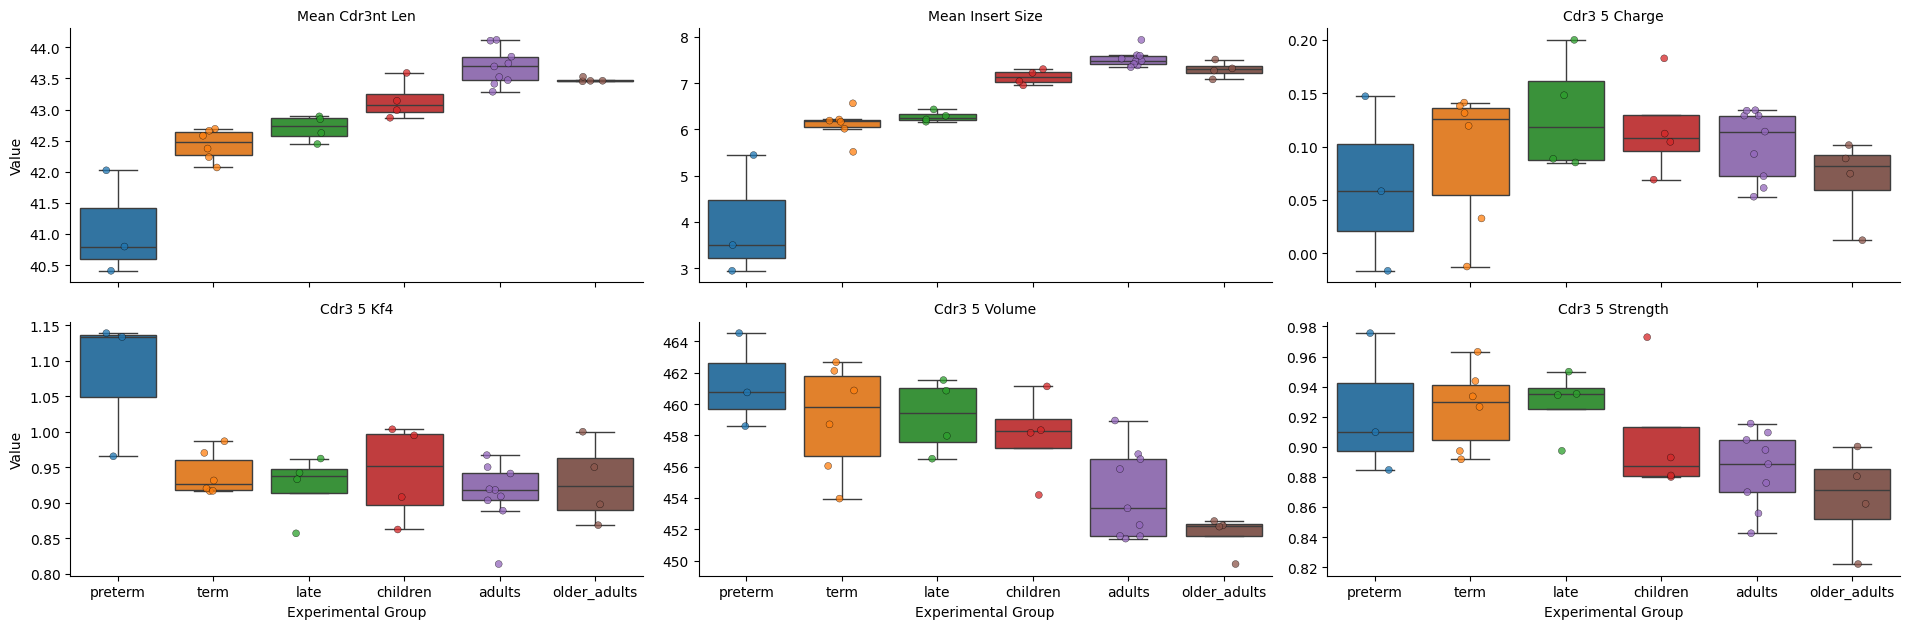

In [20]:
# Отображаем свойства CDR3 по экспериментальным группам, один образец — одно наблюдение.
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [21]:
# Медианы по группам: длина CDR3 (нт), средний размер вставок и доля CDR3 без вставок.
cdr3_summary = cdr3_properties.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["mean_cdr3nt_len", "mean_insert_size", "zero_insert_freq"]].median()
cdr3_summary.round(3)

,mean_cdr3nt_len,mean_insert_size,zero_insert_freq
experimental_group,,,
preterm,40.797,3.498,0.236
term,42.476,6.178,0.053
late,42.735,6.254,0.051
children,43.066,7.132,0.022
adults,43.694,7.480,0.020
older_adults,43.463,7.296,0.021


In [22]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

**Распределение длин CDR3.** Здесь сравниваются `preterm` (недоношенные) и `late` (поздний срок гестации) **в одной клеточной популяции**. `seq_type='aa'` задаёт длину в аминокислотах, а `count_by_freq=True` — относительные частоты, а не абсолютное число последовательностей. Ненулевые вставки при рекомбинации могут увеличивать длину CDR3; биологическая гипотеза о возрастном различии связана в том числе с активностью TdT.

На первом графике смотрим профили отдельных образцов, на втором — их группировку. 

Сдвиг распределения отражает изменение средней длины, формы распределения или обоих параметров?

Обоих, но в основном сдвигается среднее. Средняя длина CDR3 у preterm меньше примерно на 2 нт (40,8 против 42,7 нт у late), это около 0,6 аминокислоты. Общая форма похожая, одна вершина около 13-15 аминокислот, но у preterm больше коротких CDR3 (11-13 аминокислот около 44% против 31% у late) и почти в 2 раза меньше длинных (16-18 аминокислот около 11% против 20%), то есть правый хвост у preterm тоньше. Это и логично, если вставок меньше, длинных CDR3 получается меньше. При этом в группах всего 3 и 4 образца.

## CDR3len distributions

In [23]:
# Выбираем nCD4 из групп preterm и late для сравнения сроков гестации.
preterm_late_cd4 = clonosets_cd4.query("experimental_group in ['preterm', 'late']")
preterm_late_cd4

,sample_id,chain,filename,experimental_group,donor_id,subset,source
2,UCB5_nCD4_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB5,nCD4,UCB
5,UCB4_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB4,nCD4,UCB
14,UCB11_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB11,nCD4,UCB
17,UCB7_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB7,nCD4,UCB
20,UCB8_nCD4_TRB_1,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB8,nCD4,UCB
24,UCB9_nCD4_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,late,UCB9,nCD4,UCB
28,UCB1_nCD4_TRB_2,TRB,/Users/anna.shifon/Downloads/ImmuneSem 2/data/...,preterm,UCB1,nCD4,UCB


In [24]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_cd4,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nCD4_TRB_1,TRB,4,0.000000
1,UCB11_nCD4_TRB_1,TRB,5,0.000007
2,UCB11_nCD4_TRB_1,TRB,6,0.000021
3,UCB11_nCD4_TRB_1,TRB,7,0.000129
4,UCB11_nCD4_TRB_1,TRB,8,0.000371
...,...,...,...,...
156,UCB9_nCD4_TRB_2,TRB,22,0.000053
157,UCB9_nCD4_TRB_2,TRB,23,0.000038
158,UCB9_nCD4_TRB_2,TRB,24,0.000010
159,UCB9_nCD4_TRB_2,TRB,25,0.000010


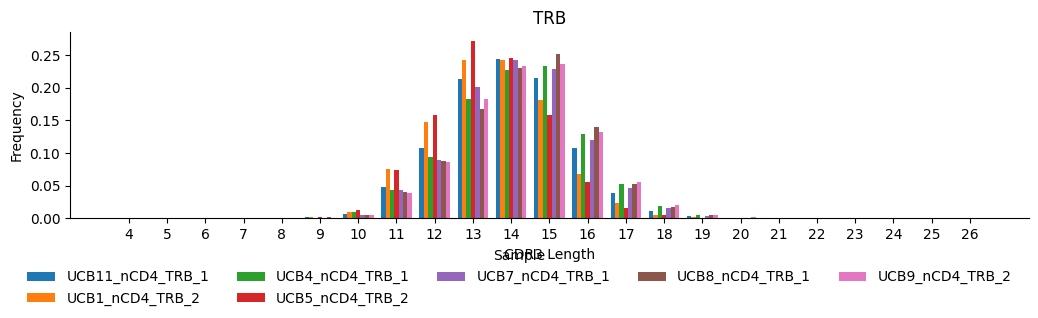

In [25]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

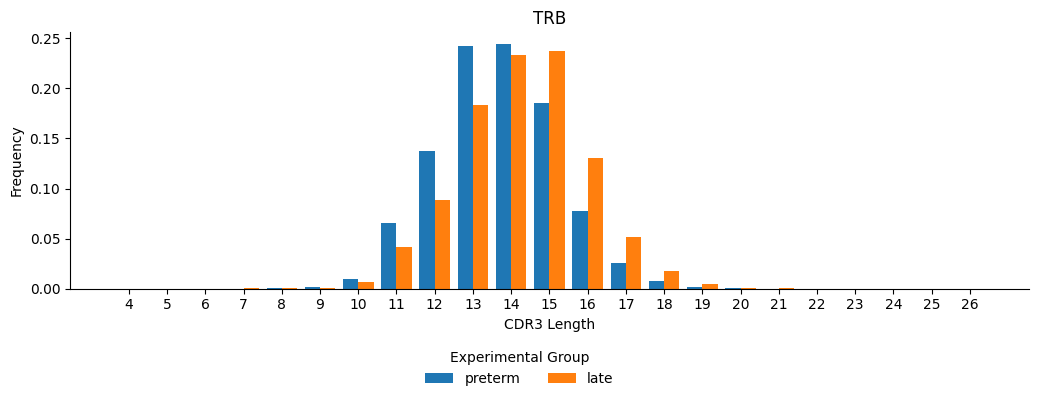

In [26]:
# Показываем те же распределения, добавляя возрастные/экспериментальные группы.
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

**Использование сегментов (segment usage).** При сборке TCR используются разные V- и J-сегменты. Их частоты не обязаны быть одинаковыми: влияют особенности рекомбинации, отбора и экспансии клонотипов. Это **описательная метрика**; высокое использование одного сегмента само по себе не доказывает ответ на определённый антиген.

`v_usage`/`j_usage` — таблицы относительного использования сегментов по образцам; тепловая карта, boxplot и barplot показывают одни данные разными способами. `combine_families=True` объединяет родственные V-гены по семействам, поэтому детализация становится грубее.

## Segment usage

### V-usage

In [27]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets_cd4, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,v,usage
0,o3_mnCD4_TRB_2,TRB,TRBV1,0.000091
1,o5_mnCD4_TRB_1,TRB,TRBV1,0.000363
2,UCB5_nCD4_TRB_2,TRB,TRBV1,0.000317
3,a11_mnCD4_TRB_1,TRB,TRBV1,0.000423
4,UCB2_nCD4_TRB_1,TRB,TRBV1,0.000251
...,...,...,...,...
1825,UCB12_mnCD4_TRB_1,TRB,TRBV12-4,0.000000
1826,a7_mnCD4_TRB_1,TRB,TRBV12-4,0.000000
1827,a1_mnCD4_TRB_1,TRB,TRBV12-4,0.000000
1828,UCB1_nCD4_TRB_2,TRB,TRBV12-4,0.000000


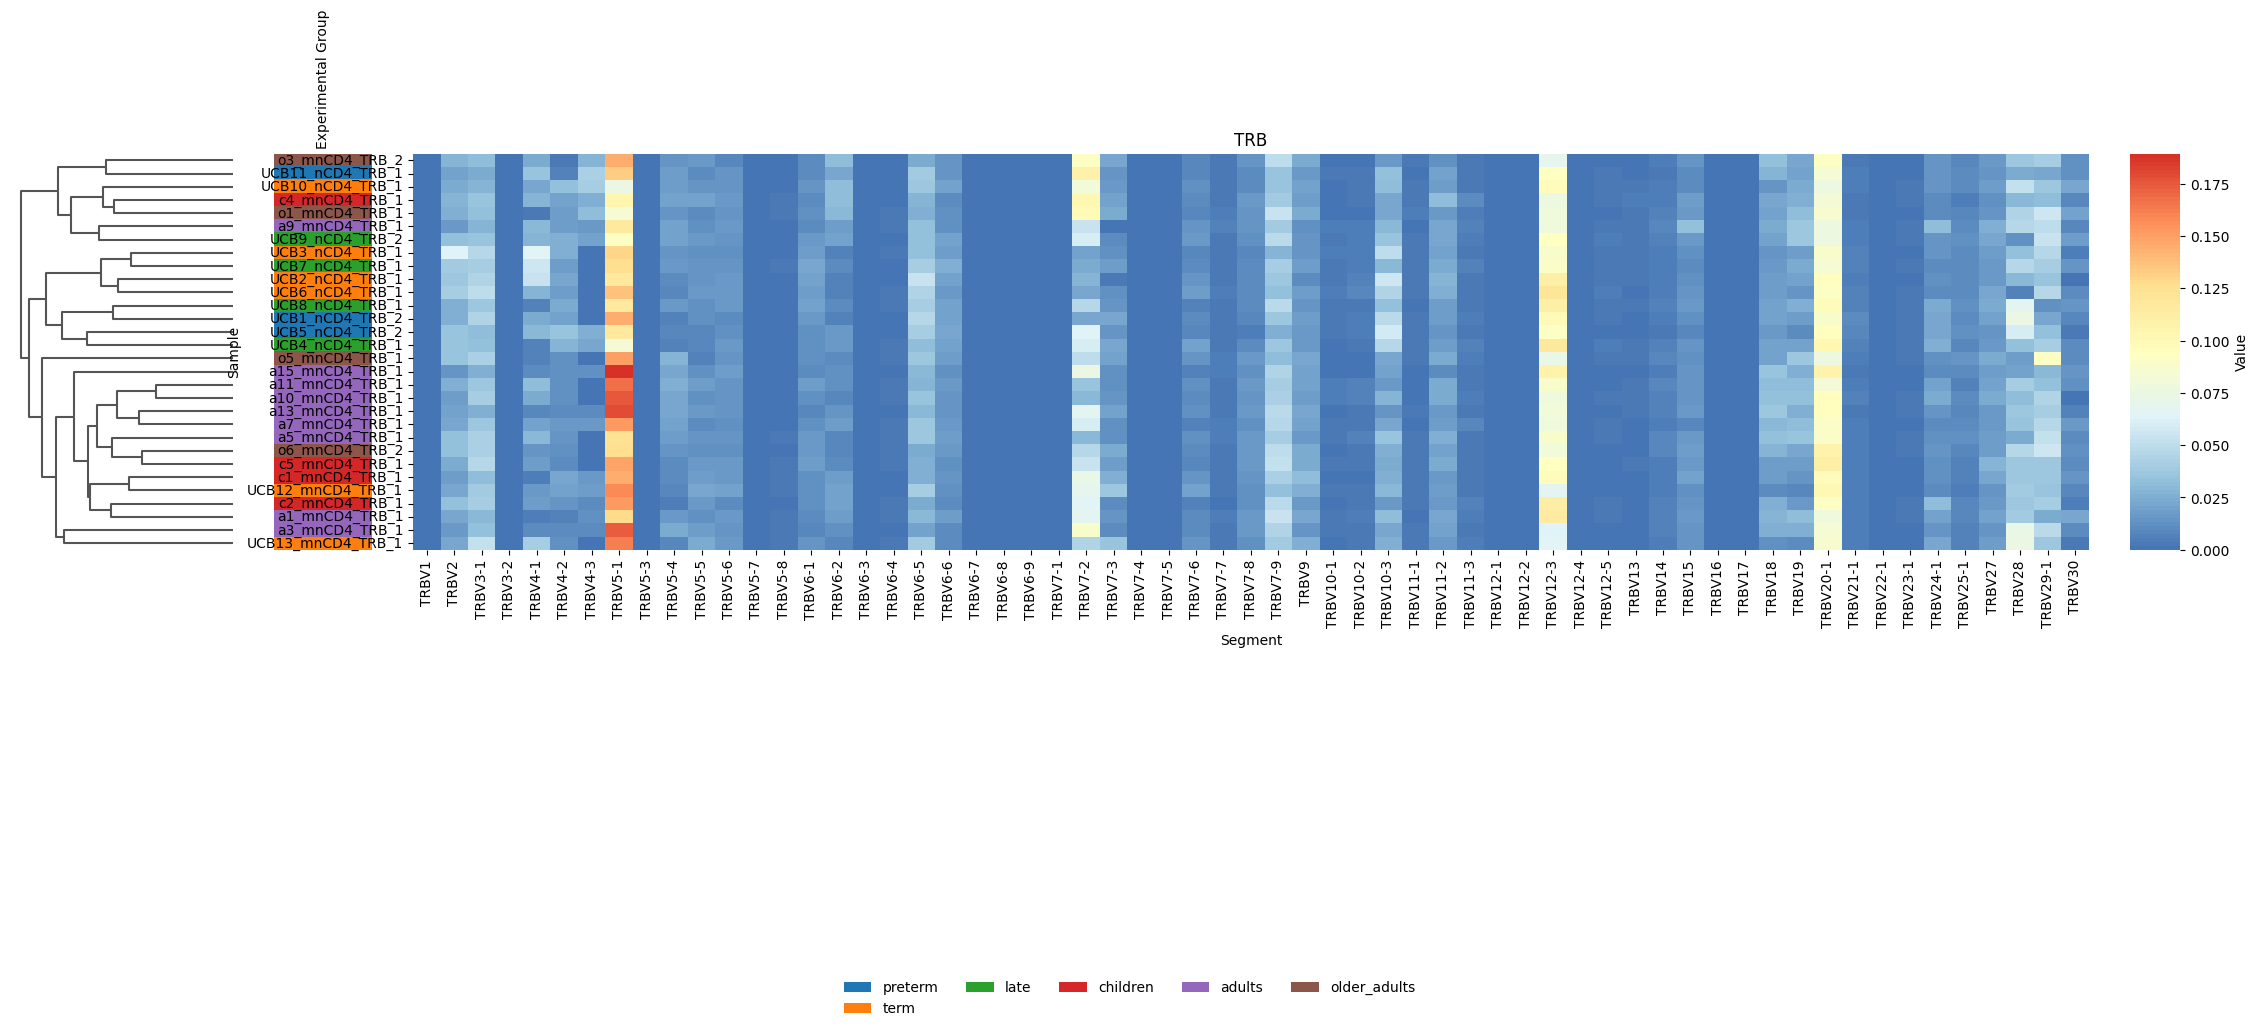

In [28]:
# Тепловая карта: образцы или группы сопоставляются по профилям использования V.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

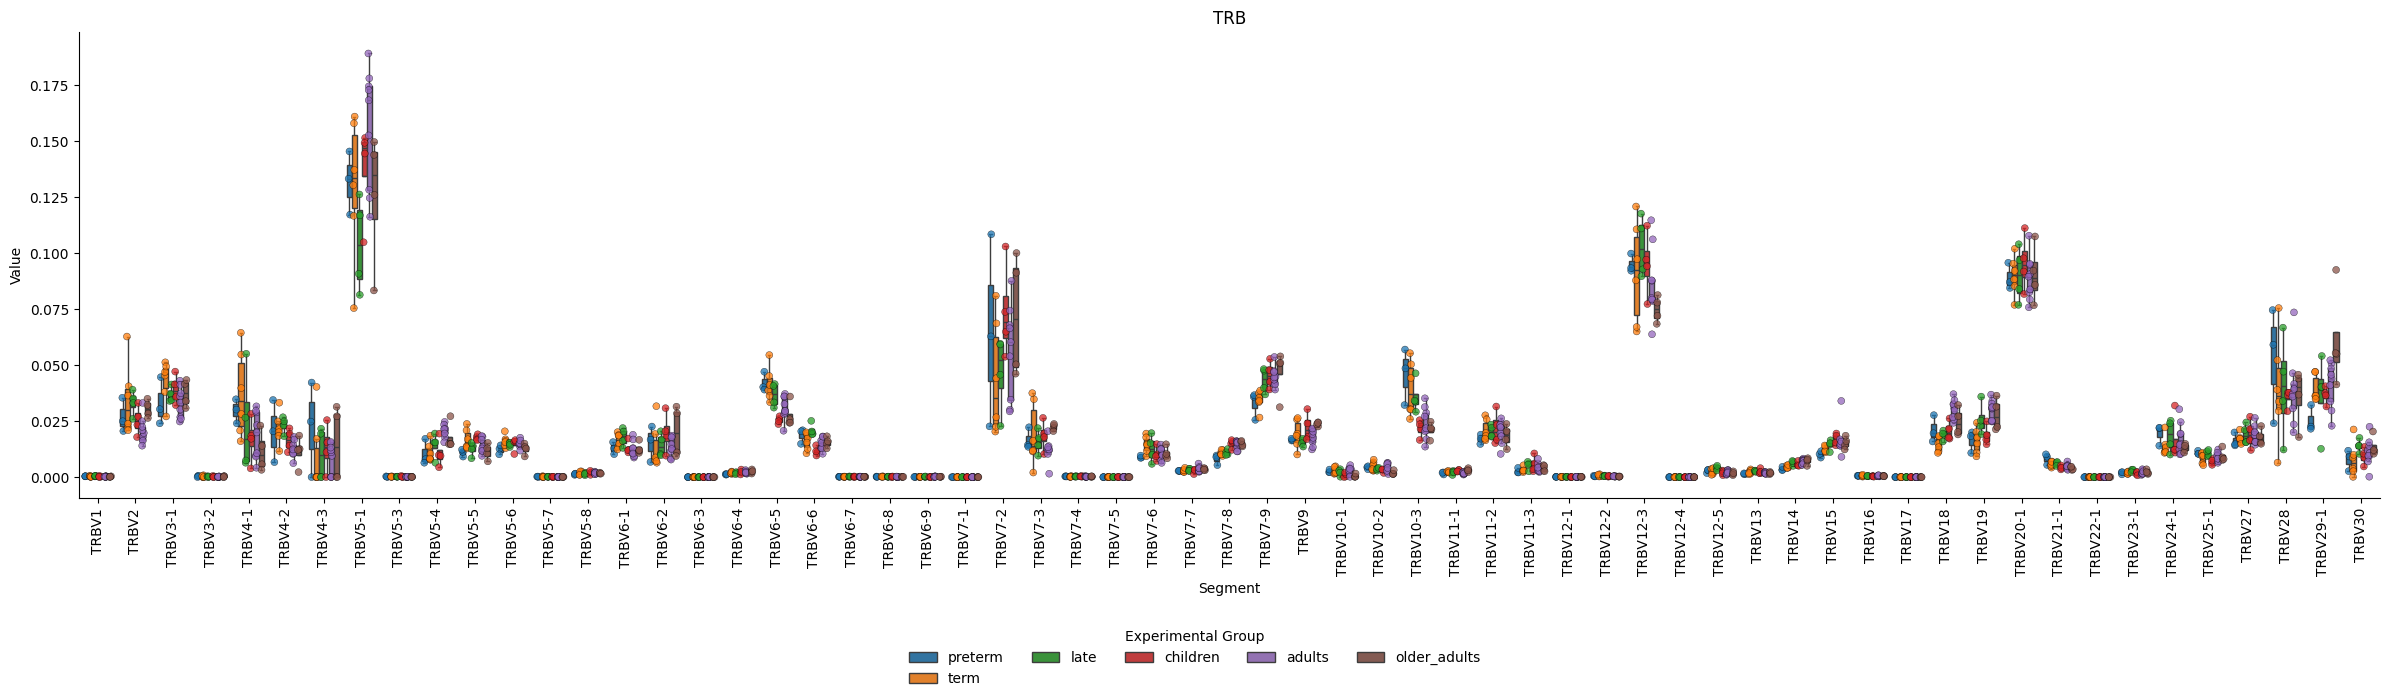

In [29]:
# Boxplot показывает вариацию использования V-сегментов между образцами групп.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

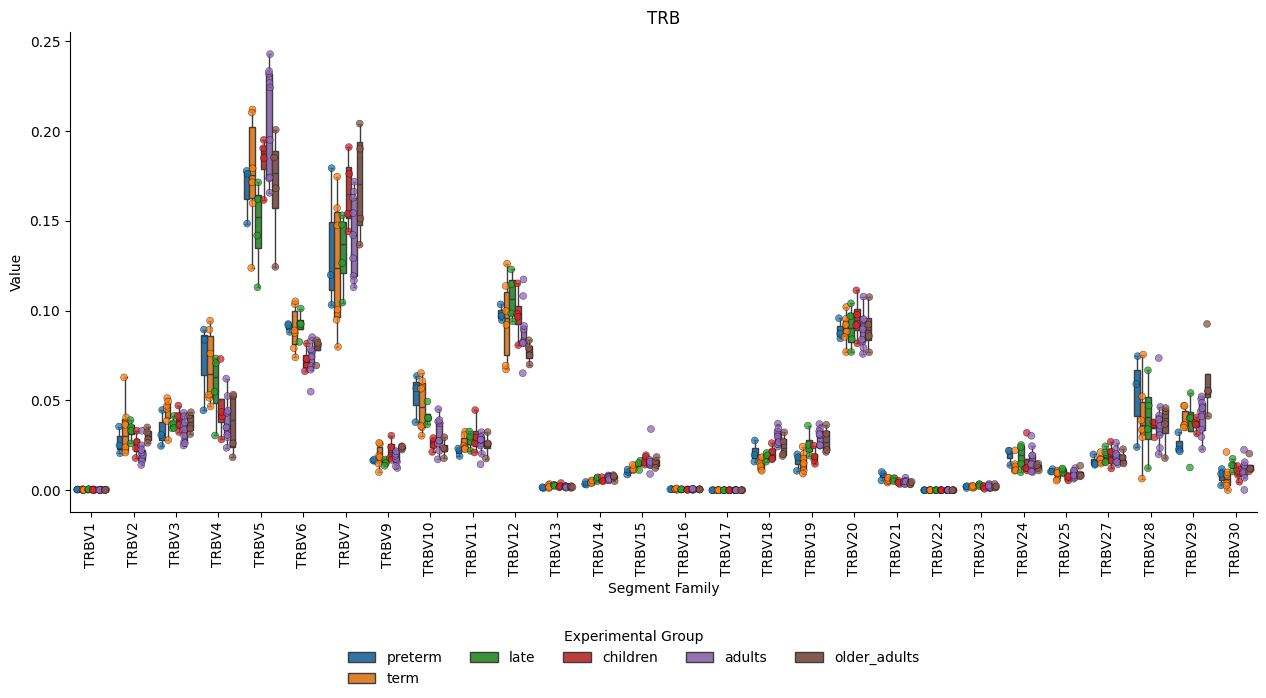

In [30]:
# Объединяем V-гены по семействам, чтобы увидеть более крупные закономерности.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

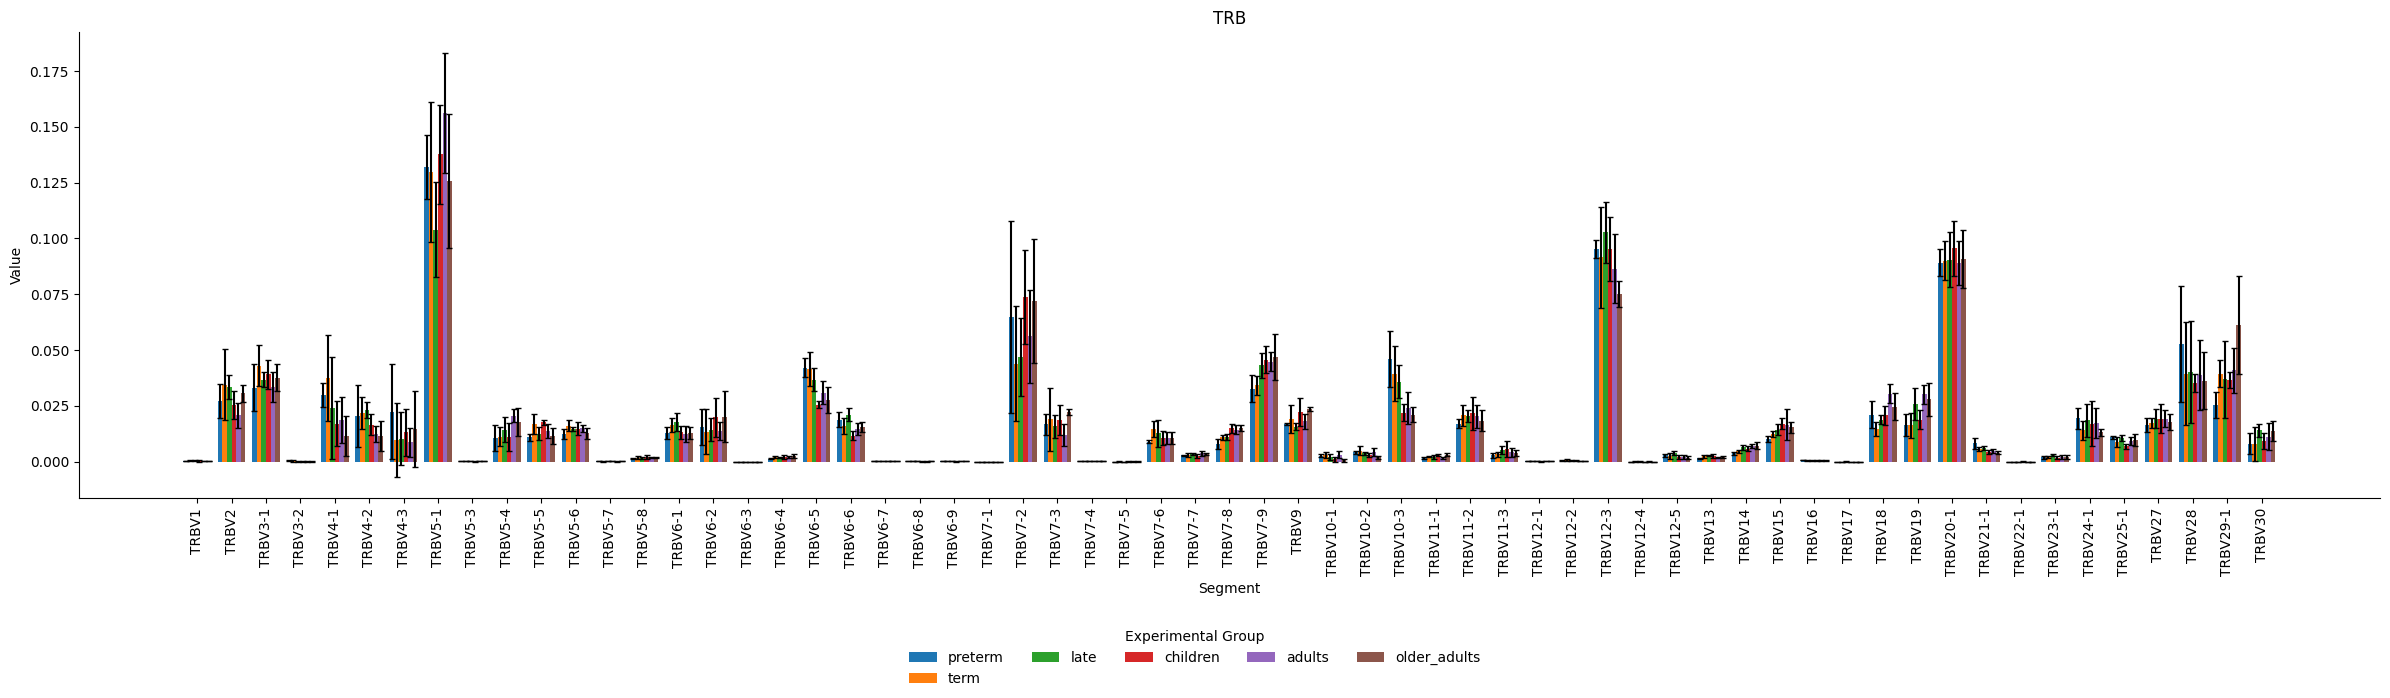

In [31]:
# Barplot показывает частоты отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

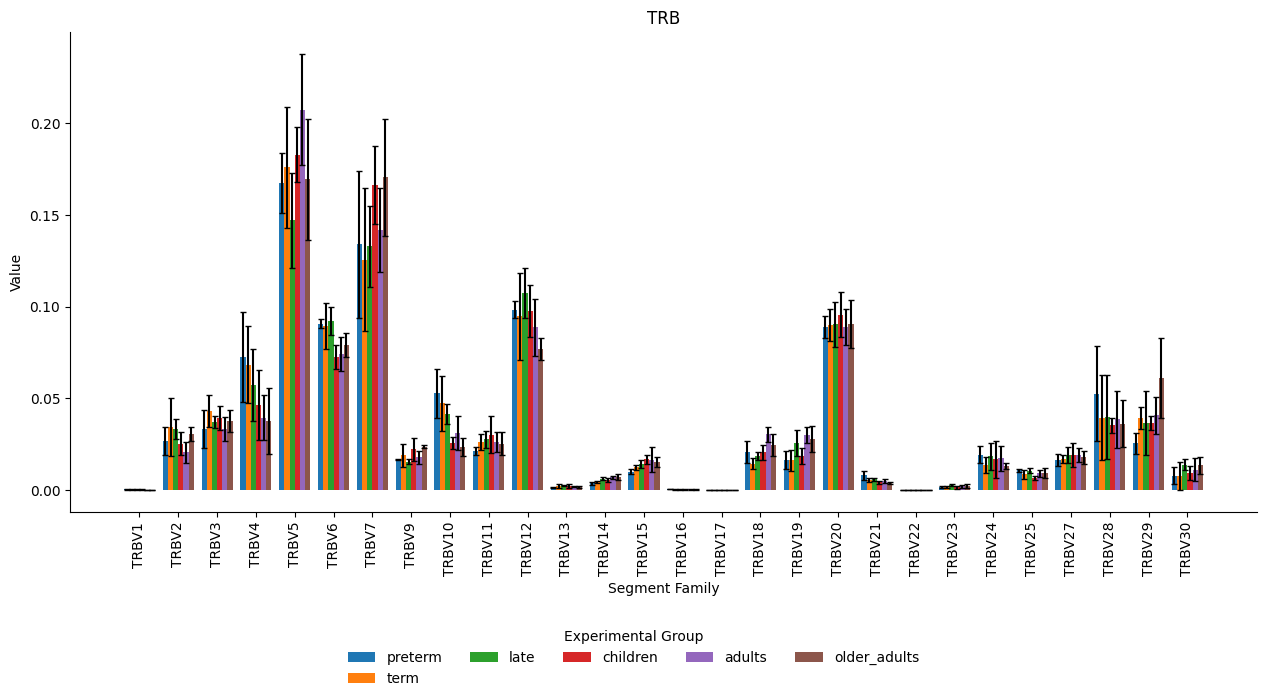

In [32]:
# Barplot для частот V-семейств вместо отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [33]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets_cd4, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,j,usage
0,o3_mnCD4_TRB_2,TRB,TRBJ1-1,0.104081
1,o5_mnCD4_TRB_1,TRB,TRBJ1-1,0.085873
2,UCB5_nCD4_TRB_2,TRB,TRBJ1-1,0.097860
3,a11_mnCD4_TRB_1,TRB,TRBJ1-1,0.081056
4,UCB2_nCD4_TRB_1,TRB,TRBJ1-1,0.124051
...,...,...,...,...
385,UCB12_mnCD4_TRB_1,TRB,TRBJ2-7,0.139813
386,a7_mnCD4_TRB_1,TRB,TRBJ2-7,0.172592
387,a1_mnCD4_TRB_1,TRB,TRBJ2-7,0.163046
388,UCB1_nCD4_TRB_2,TRB,TRBJ2-7,0.160783


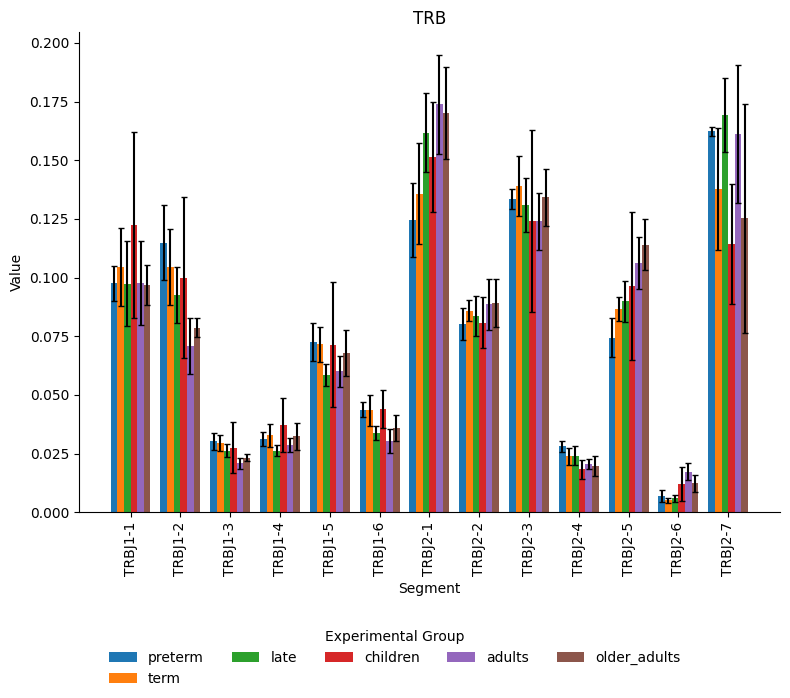

In [34]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

In [35]:
# Медиана доли каждого сегмента по образцам группы; показываем самые частые V и J.
def usage_summary(usage, segment, top=None, genes=None):
    d = usage.merge(metadata, on="sample_id")
    table = d.groupby([segment, "experimental_group"], observed=True)["usage"].median().unstack()
    table["all_samples"] = d.groupby(segment)["usage"].median()
    table = table.sort_values("all_samples", ascending=False)
    if genes is not None:
        table = table.loc[[g for g in genes if g in table.index]]
    return (100 * table.head(top) if top else 100 * table).round(1)

print("V-сегменты, медиана доли, %")
display(usage_summary(v_usage, "v", top=6))
print("J-сегменты, медиана доли, %")
display(usage_summary(j_usage, "j"))

V-сегменты, медиана доли, %


experimental_group,preterm,term,late,children,adults,older_adults,all_samples
v,,,,,,,
TRBV5-1,13.3,13.4,10.4,14.7,16.8,13.5,13.5
TRBV20-1,8.7,9.0,9.0,9.5,9.0,8.9,9.0
TRBV12-3,9.3,9.3,10.2,9.6,8.0,7.5,8.9
TRBV7-2,6.3,3.5,5.2,6.9,6.0,7.1,5.9
TRBV7-9,3.6,3.5,4.4,4.5,4.5,5.1,4.1
TRBV29-1,2.3,3.6,4.0,3.7,4.4,5.5,4.0


J-сегменты, медиана доли, %


experimental_group,preterm,term,late,children,adults,older_adults,all_samples
j,,,,,,,
TRBJ2-1,13.0,13.0,16.3,14.4,17.0,17.4,15.7
TRBJ2-7,16.2,14.1,17.2,11.9,17.1,14.5,15.3
TRBJ2-3,13.2,14.1,13.1,11.3,12.4,13.1,13.0
TRBJ1-1,9.8,9.9,9.9,13.4,10.0,9.9,10.0
TRBJ2-5,7.1,8.6,9.1,8.9,10.6,11.2,9.4
TRBJ2-2,8.4,8.6,8.3,8.1,8.9,8.6,8.4
TRBJ1-2,10.8,10.3,9.0,11.4,7.4,7.8,8.4
TRBJ1-5,7.3,7.0,5.7,7.5,5.9,6.9,6.5
TRBJ1-6,4.2,4.1,3.5,4.6,2.8,3.6,3.7


**Конвергенция нуклеотидных последовательностей.** Разные CDR3 на уровне ДНК могут кодировать **одинаковую CDR3 на уровне белка** благодаря вырожденности генетического кода и независимым событиям перестройки. Простая мера — число различных CDR3nt, делённое на число различных CDR3aa. При добавлении требований совпадения V или V+J получаются более строгие варианты (`convergence_v`, `convergence_vj`).

Конвергенция зависит также от длины CDR3 и механизма генерации последовательностей; **её увеличение само по себе не доказывает антиген-индуцированную экспансию**. Для сравнения образцов применён одинаковый даунсэмпл.

## Convergence

In [36]:
# Вычисляем конвергенцию после стандартизации глубины образцов.
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(clonosets_cd4,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence

CalcConvergence settings: seed=42, downsample=5500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_mnCD4_TRB_2, o5_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a11_mnCD4_TRB_1, UCB2_nCD4_TRB_1, UCB4_nCD4_TRB_1, c1_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB3_nCD4_TRB_1, a5_mnCD4_TRB_1, a10_mnCD4_TRB_1, a3_mnCD4_TRB_1, c4_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB11_nCD4_TRB_1, UCB13_mnCD4_TRB_1, a13_mnCD4_TRB_1, UCB7_nCD4_TRB_1, a15_mnCD4_TRB_1, o1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, o6_mnCD4_TRB_2, c5_mnCD4_TRB_1, UCB10_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB12_mnCD4_TRB_1, a7_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB6_nCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 30/30 calcultaion(s) proc

,sample_id,chain,convergence,convergence_v,convergence_vj
0,o3_mnCD4_TRB_2,TRB,1.004185,1.001138,1.001138
1,o5_mnCD4_TRB_1,TRB,1.001502,1.000429,1.000429
2,UCB5_nCD4_TRB_2,TRB,1.074952,1.017466,1.017466
3,a11_mnCD4_TRB_1,TRB,1.002392,1.000597,1.000597
4,UCB2_nCD4_TRB_1,TRB,1.007008,1.002073,1.002073
5,UCB4_nCD4_TRB_1,TRB,1.005977,1.001487,1.001487
6,c1_mnCD4_TRB_1,TRB,1.001726,1.000191,1.000191
7,a9_mnCD4_TRB_1,TRB,1.002656,1.000612,1.000612
8,UCB3_nCD4_TRB_1,TRB,1.012801,1.003070,1.003070
9,a5_mnCD4_TRB_1,TRB,1.003113,1.000194,1.000194


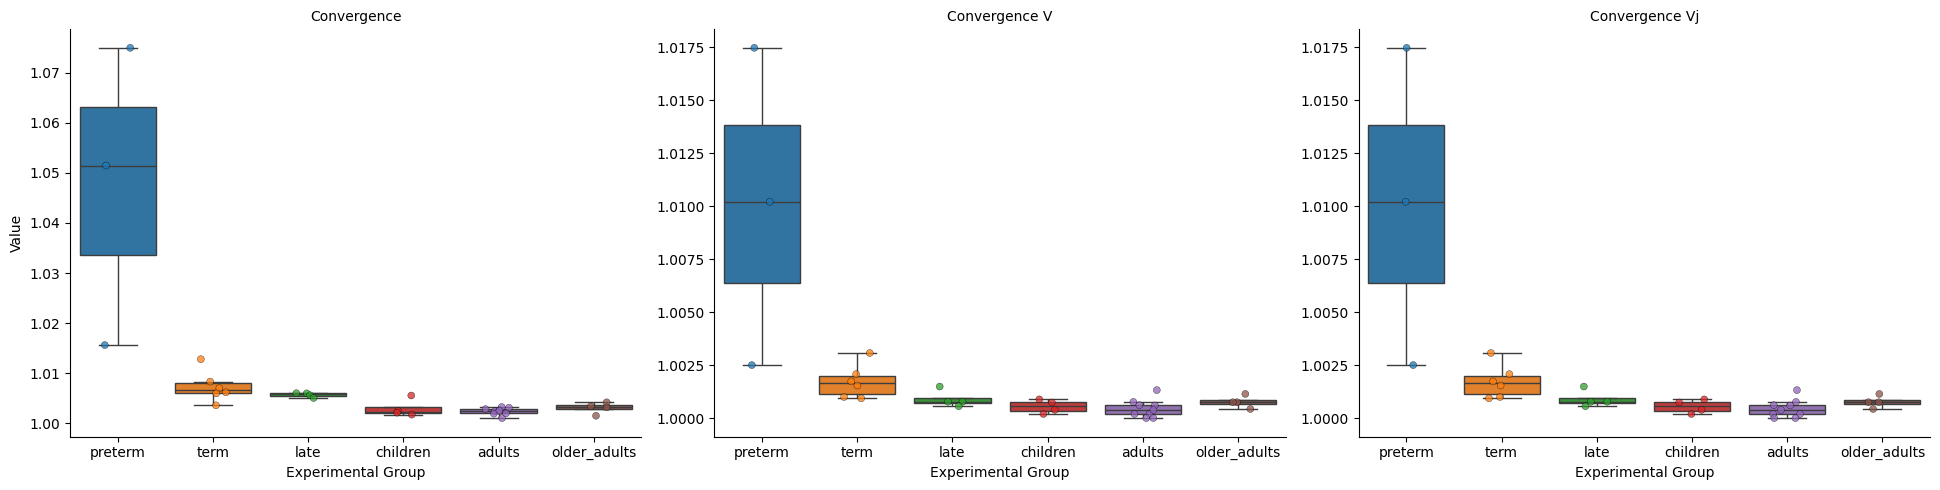

In [37]:
# Показываем конвергенцию и её варианты по экспериментальным группам.
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

In [38]:
# Медианы convergence по группам.
convergence.merge(metadata, on="sample_id").groupby(
    "experimental_group", observed=True)[["convergence", "convergence_v", "convergence_vj"]].median().round(4)

,convergence,convergence_v,convergence_vj
experimental_group,,,
preterm,1.0515,1.0102,1.0102
term,1.0066,1.0016,1.0016
late,1.0058,1.0008,1.0008
children,1.0023,1.0006,1.0006
adults,1.0025,1.0004,1.0004
older_adults,1.0033,1.0007,1.0007


**Альфа-разнообразие — разнообразие *внутри* одного образца.** Несколько важных метрик:

- **`diversity`** — число обнаруженных клонотипов (богатство); чувствительно к глубине наблюдений.
- **`shannon_wiener`**: $H=-\sum_i p_i\ln p_i$; учитывает и богатство, и равномерность частот.
- **`norm_shannon_wiener`**: нормированная мера равномерности, обычно $H/\ln S$ (при $S>1$); ближе к 1, если частоты более равномерны.
- **`clonality`** — показатель противоположной направленности: больший вклад немногих клонов означает более выраженную клональность.
- Дополнительные метрики в таблице (`chao1`, `simpson`, `inverse_simpson`, `d50`, `gini_coefficient` и др.) по-разному чувствительны к редким и частым клонотипам.

`iterations=3` повторяет случайное субсэмплирование несколько раз; сравнивайте группы по распределению **образцов**, не воспринимая эти повторы как новые независимые биологические реплики. В данном примере настройка `seed` в самой функции и в фильтре могут различаться — ориентируйтесь на параметры расчёта в её логе.

## Diversity stats

In [39]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets_cd4,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False, 
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats settings: seed=123, downsample=5500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_mnCD4_TRB_2, o5_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a11_mnCD4_TRB_1, UCB2_nCD4_TRB_1, UCB4_nCD4_TRB_1, c1_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB3_nCD4_TRB_1, a5_mnCD4_TRB_1, a10_mnCD4_TRB_1, a3_mnCD4_TRB_1, c4_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB11_nCD4_TRB_1, UCB13_mnCD4_TRB_1, a13_mnCD4_TRB_1, UCB7_nCD4_TRB_1, a15_mnCD4_TRB_1, o1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, o6_mnCD4_TRB_2, c5_mnCD4_TRB_1, UCB10_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB12_mnCD4_TRB_1, a7_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB6_nCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(

,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,o3_mnCD4_TRB_2,TRB,5306.0,0.998408,0.001592,8.562939,78081.116667,5306.0,77932.313372,0.069273,0.481719,0.000195,5125.381227,0.999805,0.000545,0.034073
1,o5_mnCD4_TRB_1,TRB,4724.0,0.993278,0.006722,8.403542,19436.119217,4724.0,19983.162750,0.260545,0.417866,0.000244,4106.706489,0.999756,0.001455,0.124119
2,UCB5_nCD4_TRB_2,TRB,5109.0,0.996537,0.003463,8.509191,41929.464286,5109.0,42372.044193,0.134000,0.461734,0.000211,4735.441453,0.999789,0.000909,0.066778
3,a11_mnCD4_TRB_1,TRB,5059.0,0.996418,0.003582,8.498370,33256.462141,5059.0,33302.550551,0.154909,0.456414,0.000213,4692.832765,0.999787,0.000727,0.074083
4,UCB2_nCD4_TRB_1,TRB,5334.0,0.998618,0.001382,8.569997,93411.138158,5334.0,93128.928035,0.059091,0.484439,0.000193,5174.478276,0.999807,0.000545,0.029318
5,UCB4_nCD4_TRB_1,TRB,4779.0,0.994078,0.005922,8.421816,20170.469534,4779.0,20249.100001,0.246364,0.424566,0.000236,4237.881760,0.999764,0.000727,0.115574
6,c1_mnCD4_TRB_1,TRB,5275.0,0.998101,0.001899,8.554459,70348.685279,5275.0,69843.251778,0.079273,0.478673,0.000198,5060.220810,0.999802,0.000545,0.039368
7,a9_mnCD4_TRB_1,TRB,4970.0,0.988938,0.011062,8.417028,39389.000000,4970.0,47908.804258,0.160000,0.446680,0.000405,2466.568819,0.999595,0.012364,0.091800
8,UCB3_nCD4_TRB_1,TRB,5259.0,0.998062,0.001938,8.551093,60866.048458,5259.0,60893.684211,0.086364,0.477087,0.000198,5045.030020,0.999802,0.000545,0.041923
9,a5_mnCD4_TRB_1,TRB,5176.0,0.997361,0.002639,8.529221,46042.020690,5176.0,45851.539747,0.114727,0.468702,0.000204,4893.238434,0.999796,0.000545,0.055588


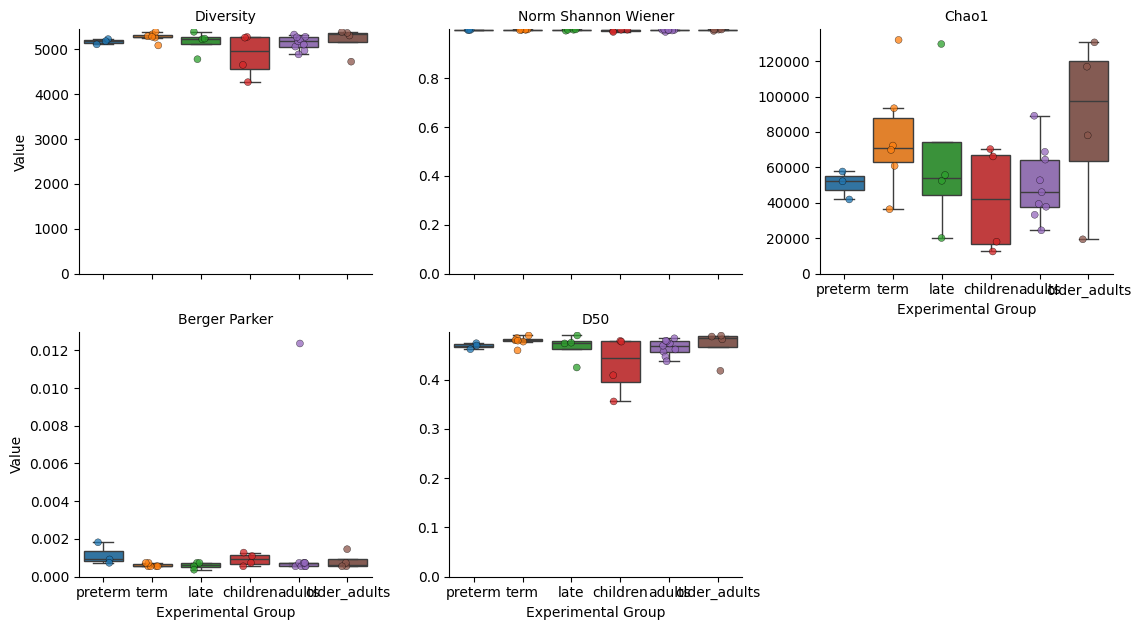

In [40]:
# Визуализируем богатство, равномерность, клональность и другие индексы.
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )

In [41]:
# Медианы метрик разнообразия по группам (повторы субсэмплирования сначала усредняем внутри образца).
div_cols = ["diversity", "shannon_wiener", "norm_shannon_wiener", "clonality", "goods_coverage", "berger_parker"]
div_cols = [c for c in div_cols if c in diversity_stats.columns]
div_per_sample = diversity_stats.groupby("sample_id")[div_cols].mean().reset_index().merge(metadata, on="sample_id")
display(div_per_sample.groupby("experimental_group", observed=True)[div_cols].median().round(4))

# Образцы с самой высокой клональностью и самым крупным клоном (berger_parker = доля крупнейшего клонотипа).
div_per_sample.sort_values("clonality", ascending=False)[["sample_id", "experimental_group"] + div_cols].head(5).round(4)

,diversity,shannon_wiener,norm_shannon_wiener,clonality,goods_coverage,berger_parker
experimental_group,,,,,,
preterm,5181.0,8.5286,0.9972,0.0028,0.1098,0.0009
term,5284.0,8.5570,0.9982,0.0018,0.0766,0.0005
late,5230.5,8.5437,0.9978,0.0022,0.0965,0.0006
children,4955.5,8.4669,0.9953,0.0047,0.1835,0.0009
adults,5176.0,8.5292,0.9974,0.0026,0.1147,0.0007
older_adults,5335.5,8.5703,0.9986,0.0014,0.0585,0.0006


,sample_id,experimental_group,diversity,shannon_wiener,norm_shannon_wiener,clonality,goods_coverage,berger_parker
23,c2_mnCD4_TRB_1,children,4268.0,8.2660,0.9889,0.0111,0.3904,0.0011
21,a9_mnCD4_TRB_1,adults,4970.0,8.4170,0.9889,0.0111,0.1600,0.0124
24,c4_mnCD4_TRB_1,children,4652.0,8.3837,0.9927,0.0073,0.2824,0.0013
28,o5_mnCD4_TRB_1,older_adults,4724.0,8.4035,0.9933,0.0067,0.2605,0.0015
7,UCB4_nCD4_TRB_1,late,4779.0,8.4218,0.9941,0.0059,0.2464,0.0007


**Rarefaction (кривые разрежения).** Для каждого образца считаем, сколько различных клонотипов обнаружилось бы при разных глубинах выборки. По оси X — `rarefaction_depth` (число наблюдений), по оси Y — ожидаемое обнаруженное богатство `diversity`.

Если кривая выходит на плато, новые наблюдения добавляют мало новых клонотипов. Для TCR-репертуара всего организма плато часто недостижимо на небольшом образце крови. **Не путать** насыщение секвенирования конкретной библиотеки ридами с насыщением биологического репертуара организма. Два графика отличаются только логарифмической/линейной шкалой X.

## Rarefaction

In [42]:
# Для каждого образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_cd4, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nCD4_TRB_1,TRB,32,32.000000
1,UCB10_nCD4_TRB_1,TRB,100,100.000000
2,UCB10_nCD4_TRB_1,TRB,316,316.000000
3,UCB10_nCD4_TRB_1,TRB,1000,995.333333
4,UCB10_nCD4_TRB_1,TRB,3162,3123.000000
...,...,...,...,...
239,o6_mnCD4_TRB_2,TRB,3162,3118.333333
240,o6_mnCD4_TRB_2,TRB,10000,9570.000000
241,o6_mnCD4_TRB_2,TRB,31623,27684.000000
242,o6_mnCD4_TRB_2,TRB,100000,69475.333333


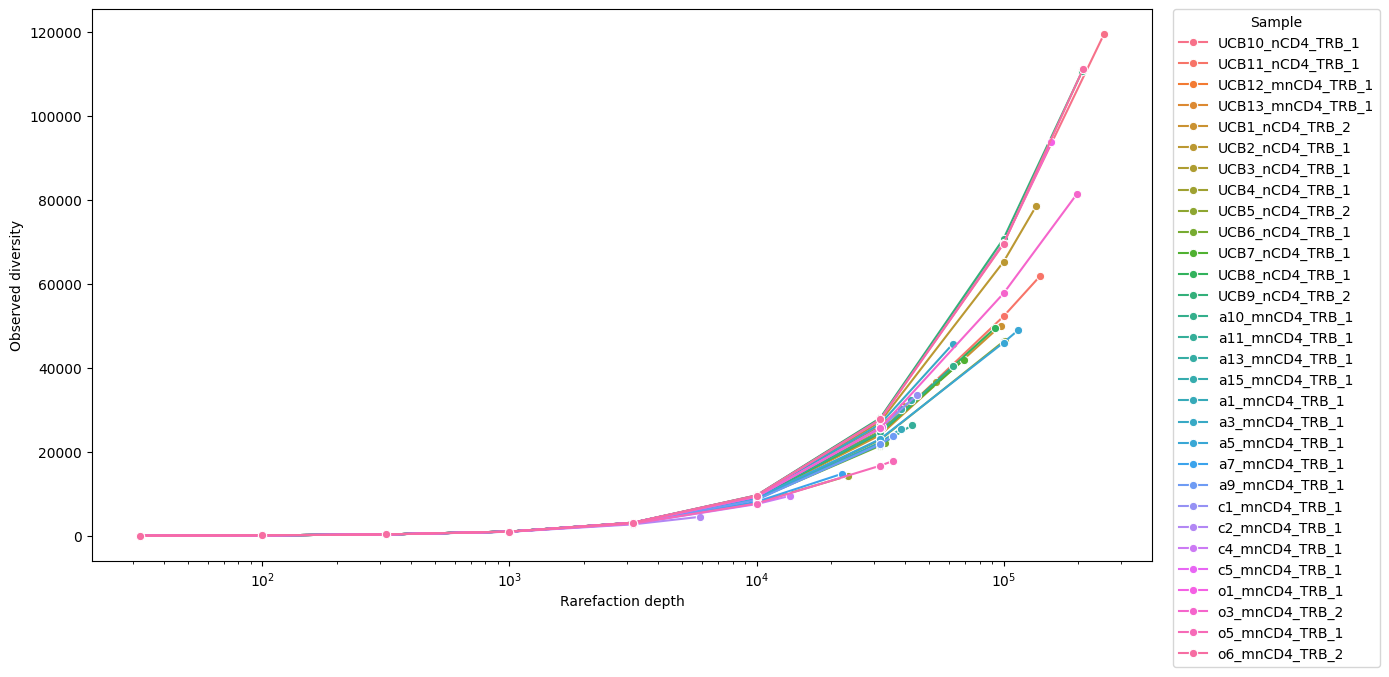

In [43]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

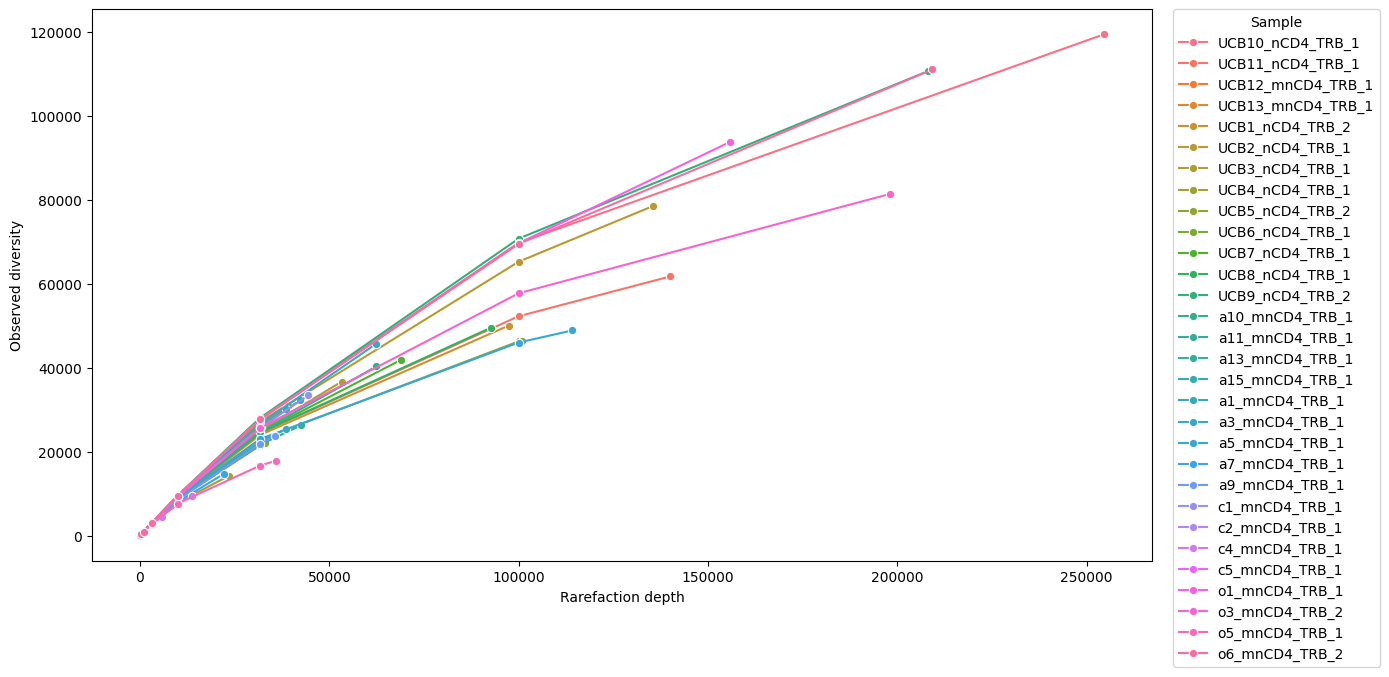

In [44]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

**Бета-разнообразие — сходство *между* образцами.** Мы сравниваем не просто численность клонов, а пересечение определённых последовательностей. В этом ноутбуке совпадение задаётся `overlap_type='aaV'`: **одинаковая аминокислотная CDR3 и один V-ген**. Совпадение только CDR3aa без учёта V — менее строгое правило.

Для двух репертуаров $A$ и $B$ метрика **F2** выражается как $F_2(A,B)=\sum_{i\in A\cap B}\sqrt{p_iq_i}$, где $p_i$, $q_i$ — частоты совпавшего клонотипа в каждом образце. Чем больше F2, тем выше сходство по совпадающим последовательностям с учётом их частот. Диагональ матрицы при одинаковых правилах определения клонотипа равна 1; почти нулевые значения между людьми ожидаемы из-за индивидуального разнообразия TCR.

Это **описательная мера сходства**, а не p-value и не результат теста на различия между экспериментальными группами.

## Beta-diversity

### Main function for beta-diversity 

**`beta.metrics`** function calculates a diverse set of Beta-diversity metrics which include (for more detailed explanation refer to **THIS LINK**):

- Number of intersecting clonotypes ('number_of_intersecting_clonotypes')
- Relative diversity ('relative_diversity')
- Pearson correlation ('pearson')
- F1 ('f1') metric - geometric mean of total frequencies of intersecting clonotypes in both samples
- F2 ('f2') metric - sum of geometric means of frequencies of each clonotype in the samples
- ', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'

Required input is only the sample_df - DataFrame with the set of repertoires

By default it outputs a dictionary, containing metrics as keys and DataFrames with each metric (or mainly matrices) as values.

In [45]:
# Считаем попарное сходство клоносетов и таблицы пересечений.
# # aaV означает совпадение CDR3aa И V-гена; значение F2 — сходство, не расстояние.
beta_diversity = beta.metrics(clonosets_cd4,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=None                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 30/30 sample(s) processed
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Intersecting clonosets |##################################################| 435/435 pairs processed


In [46]:
# Смотрим, какие метрики и таблицы вернула функция beta.metrics.
beta_diversity.keys()

dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [47]:
# Отдельно открываем квадратную матрицу попарного сходства F2.
beta_diversity["f2"]

sample2,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB12_mnCD4_TRB_1,UCB13_mnCD4_TRB_1,UCB1_nCD4_TRB_2,UCB2_nCD4_TRB_1,UCB3_nCD4_TRB_1,UCB4_nCD4_TRB_1,UCB5_nCD4_TRB_2,UCB6_nCD4_TRB_1,...,a7_mnCD4_TRB_1,a9_mnCD4_TRB_1,c1_mnCD4_TRB_1,c2_mnCD4_TRB_1,c4_mnCD4_TRB_1,c5_mnCD4_TRB_1,o1_mnCD4_TRB_1,o3_mnCD4_TRB_2,o5_mnCD4_TRB_1,o6_mnCD4_TRB_2
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nCD4_TRB_1,1.000000,0.004771,0.002514,0.002514,0.006993,0.001893,0.002647,0.003814,0.007867,0.001530,...,0.001348,0.001530,0.000727,0.001317,0.000860,0.002226,0.000909,0.000364,0.000803,0.000621
UCB11_nCD4_TRB_1,0.004771,1.000000,0.003605,0.006408,0.018767,0.002075,0.004640,0.003286,0.018912,0.002332,...,0.002984,0.000909,0.001712,0.002337,0.002102,0.000909,0.001893,0.001680,0.001011,0.001091
UCB12_mnCD4_TRB_1,0.002514,0.003605,1.000000,0.002847,0.006124,0.000984,0.004448,0.001166,0.010324,0.001273,...,0.001406,0.000909,0.000364,0.000984,0.000936,0.000439,0.001423,0.000909,0.002345,0.000257
UCB13_mnCD4_TRB_1,0.002514,0.006408,0.002847,1.000000,0.011452,0.003060,0.006691,0.004151,0.014475,0.002696,...,0.000545,0.000727,0.001499,0.001166,0.001348,0.000727,0.000727,0.000727,0.001530,0.002075
UCB1_nCD4_TRB_2,0.006993,0.018767,0.006124,0.011452,1.000000,0.010174,0.017519,0.008019,0.050591,0.005445,...,0.003782,0.003275,0.004040,0.003537,0.002044,0.002208,0.002847,0.004554,0.003162,0.002133
UCB2_nCD4_TRB_1,0.001893,0.002075,0.000984,0.003060,0.010174,1.000000,0.004510,0.002847,0.008006,0.001756,...,0.000545,0.001060,0.001060,0.000878,0.000878,0.001273,0.000984,0.000439,0.002616,0.000545
UCB3_nCD4_TRB_1,0.002647,0.004640,0.004448,0.006691,0.017519,0.004510,1.000000,0.004749,0.021330,0.002771,...,0.000878,0.001091,0.002740,0.000621,0.002157,0.001530,0.001060,0.001893,0.001556,0.001862
UCB4_nCD4_TRB_1,0.003814,0.003286,0.001166,0.004151,0.008019,0.002847,0.004749,1.000000,0.007506,0.001893,...,0.001091,0.001793,0.000727,0.001530,0.001135,0.000860,0.001663,0.001273,0.000621,0.000727
UCB5_nCD4_TRB_2,0.007867,0.018912,0.010324,0.014475,0.050591,0.008006,0.021330,0.007506,1.000000,0.006155,...,0.002847,0.003824,0.002904,0.003849,0.003908,0.002953,0.002439,0.003712,0.002408,0.002616


In [48]:
import numpy as np

# Средний F2 внутри групп и между группами (диагональ, то есть сравнение образца с самим собой, исключаем).
f2 = beta_diversity["f2"]
f2_pairs = f2.where(~np.eye(len(f2), dtype=bool)).stack().rename("f2").reset_index()
f2_pairs.columns = ["sample_id_1", "sample_id_2", "f2"]
group_of = metadata.set_index("sample_id")["experimental_group"]
f2_pairs["group_1"] = f2_pairs["sample_id_1"].map(group_of)
f2_pairs["group_2"] = f2_pairs["sample_id_2"].map(group_of)
print("Медиана F2 по всем парам:", round(f2_pairs["f2"].median(), 5))
f2_pairs.groupby(["group_1", "group_2"], observed=True)["f2"].mean().unstack().round(4)

Медиана F2 по всем парам: 0.00117


group_2,preterm,term,late,children,adults,older_adults
group_1,,,,,,
preterm,0.0294,0.0083,0.0070,0.0027,0.0027,0.0025
term,0.0083,0.0028,0.0027,0.0012,0.0011,0.0012
late,0.0070,0.0027,0.0022,0.0012,0.0011,0.0008
children,0.0027,0.0012,0.0012,0.0008,0.0007,0.0008
adults,0.0027,0.0011,0.0011,0.0007,0.0008,0.0009
older_adults,0.0025,0.0012,0.0008,0.0008,0.0009,0.0005


In [49]:
# Самые похожие пары образцов (каждая пара один раз).
f2_unique = f2_pairs[f2_pairs["sample_id_1"] < f2_pairs["sample_id_2"]]
f2_unique.sort_values("f2", ascending=False).head(8).round(4)

,sample_id_1,sample_id_2,f2,group_1,group_2
123,UCB1_nCD4_TRB_2,UCB5_nCD4_TRB_2,0.0506,preterm,preterm
181,UCB3_nCD4_TRB_1,UCB5_nCD4_TRB_2,0.0213,term,preterm
36,UCB11_nCD4_TRB_1,UCB5_nCD4_TRB_2,0.0189,preterm,preterm
32,UCB11_nCD4_TRB_1,UCB1_nCD4_TRB_2,0.0188,preterm,preterm
121,UCB1_nCD4_TRB_2,UCB3_nCD4_TRB_1,0.0175,preterm,term
94,UCB13_mnCD4_TRB_1,UCB5_nCD4_TRB_2,0.0145,term,preterm
90,UCB13_mnCD4_TRB_1,UCB1_nCD4_TRB_2,0.0115,term,preterm
241,UCB5_nCD4_TRB_2,UCB7_nCD4_TRB_1,0.0104,preterm,late


In [50]:
# Проверка родства: не из одной ли семьи самые похожие образцы.
metadata_raw.query("subset == 'nCD4'")[["sample_id", "experimental_group", "family", "sex", "gestational_age"]].sort_values("family")

,sample_id,experimental_group,family,sex,gestational_age
69,a13_mnCD4_TRB_1,adults,a13_a14_siblings,M,NaN
70,a15_mnCD4_TRB_1,adults,a15_a16_siblings,M,NaN
76,a3_mnCD4_TRB_1,adults,a2_a3_siblings,M,NaN
80,a9_mnCD4_TRB_1,adults,a8_a9_siblings,M,NaN
14,c2_mnCD4_TRB_1,children,c2_c3_siblings,F,NaN
6,o5_mnCD4_TRB_1,older_adults,o4_o5_siblings,M,NaN
0,o1_mnCD4_TRB_1,older_adults,NaN,M,NaN
3,o3_mnCD4_TRB_2,older_adults,NaN,M,NaN
8,o6_mnCD4_TRB_2,older_adults,NaN,M,NaN
16,c1_mnCD4_TRB_1,children,NaN,F,NaN


In [51]:
# Разбираем пересечение двух конкретных репертуаров (UCB10 и UCB11, nCD4) на уровне клонотипов.
full_table = beta_diversity["full_table"]
full_table[full_table["pair"].str.contains("UCB10_nCD4_TRB_1") & full_table["pair"].str.contains("UCB11_nCD4_TRB_1")]

,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CASSHPTTGNTIYF,TRBV3-1,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
1,CAISESVFARGQETQYF,TRBV10-3,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
2,CASSYSAGRTEAFF,TRBV6-5,0,1,0.000000,0.000182,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
3,CASSLRTDYQPQHF,TRBV28,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
4,CSARDEQQFGEQYF,TRBV20-1,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
...,...,...,...,...,...,...,...,...,...
10535,CASSLNRAEQYF,TRBV5-1,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
10536,CSARDRDQRLF,TRBV20-1,1,0,0.000182,0.000000,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
10537,CASSGTGGKTQYF,TRBV25-1,0,2,0.000000,0.000364,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1
10538,CASMWDSTRKTQYF,TRBV2,0,1,0.000000,0.000182,UCB10_nCD4_TRB_1,UCB11_nCD4_TRB_1,UCB10_nCD4_TRB_1_vs_UCB11_nCD4_TRB_1


**Как читать тепловую карту F2.** Каждая ячейка — результат сравнения **пары образцов**, а не отдельного клонотипа. `ignore_diagonal=True` убирает тривиальные сравнения образца с самим собой; `hclust=True` упорядочивает образцы иерархической кластеризацией. На карте можно искать группы похожих образцов, но визуальный кластер сам по себе не гарантирует статистическую значимость.

### Single metric heatmap plot

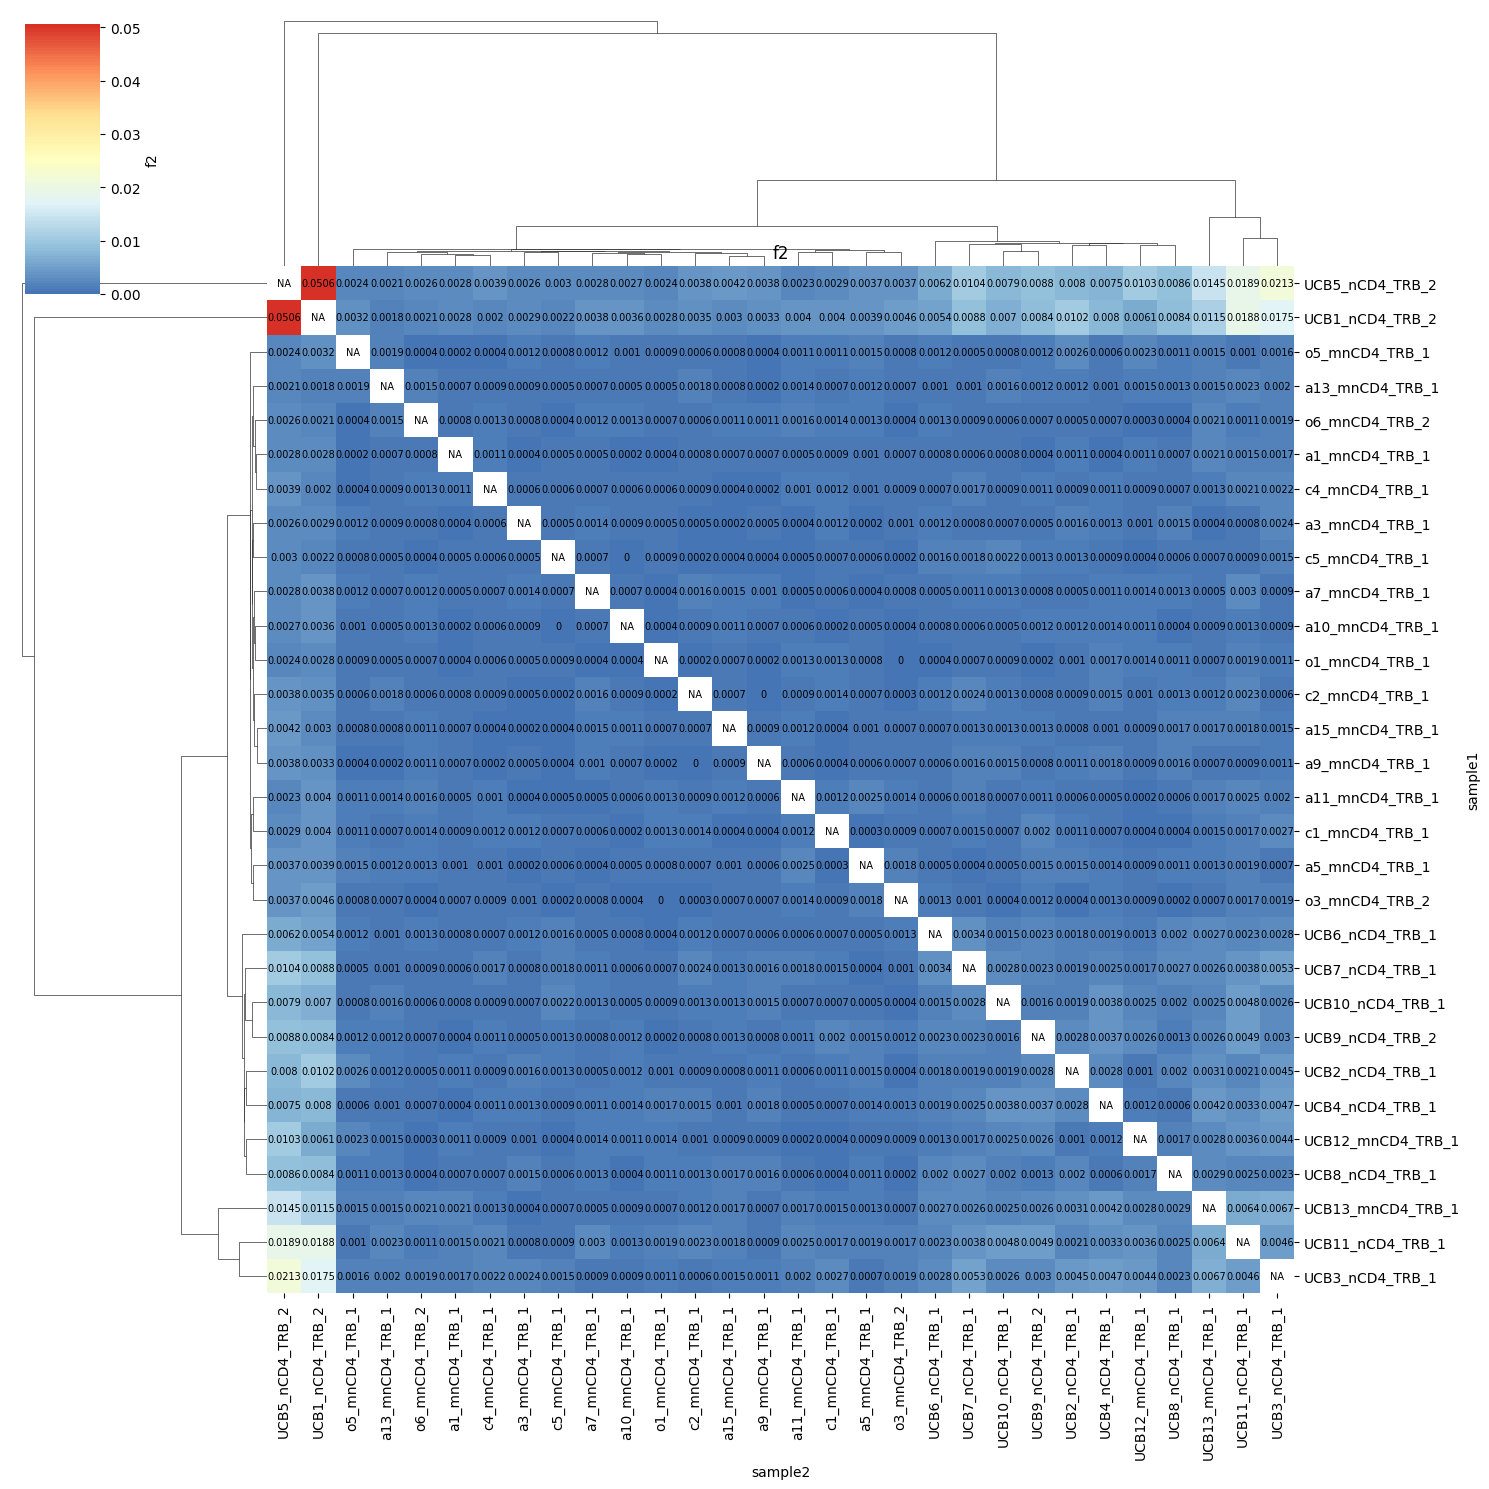

In [52]:
# Показываем тепловую карту F2, скрываем диагональ, кластеризуем образцы по сходству.
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )

**MDS (multidimensional scaling).** Это способ разместить образцы в двумерном пространстве так, чтобы **более близким** в смысле исходной матрицы расстояний объектам соответствовали более близкие точки. Мера F2 — *сходство*, поэтому для методов расстояний её преобразуют (например, в материалах семинара обсуждается $d_{ij}=-\log_{10}(F2_{ij}+\varepsilon)$ с малым $\varepsilon$). Конкретные внутренние вычисления определяет реализация `beta.mds`.

`MDS1` и `MDS2` — **условные координаты**, а не биологические параметры. `centroids=True` показывает центры групп, `dispersion=True` — разброс. Оцениваем, насколько образцы одной группы сближаются; не делаем вывод о значимости без отдельного статистического анализа.

### MDS for metric

In [53]:
# Преобразуем информацию о попарных отношениях между образцами в координаты MDS.
ucb_cd4_mds = beta.mds(beta_diversity)
ucb_cd4_mds

,sample_id,MDS1,MDS2
0,UCB10_nCD4_TRB_1,0.601960,-0.301828
1,UCB11_nCD4_TRB_1,-0.026440,0.198513
2,UCB12_mnCD4_TRB_1,-0.024831,-0.256622
3,UCB13_mnCD4_TRB_1,0.053422,0.077294
4,UCB1_nCD4_TRB_2,-0.058416,-0.198084
5,UCB2_nCD4_TRB_1,0.327454,-0.238498
6,UCB3_nCD4_TRB_1,0.165293,-0.280823
7,UCB4_nCD4_TRB_1,-0.069611,-0.304284
8,UCB5_nCD4_TRB_2,0.018997,-0.231326
9,UCB6_nCD4_TRB_1,0.007622,-0.181096


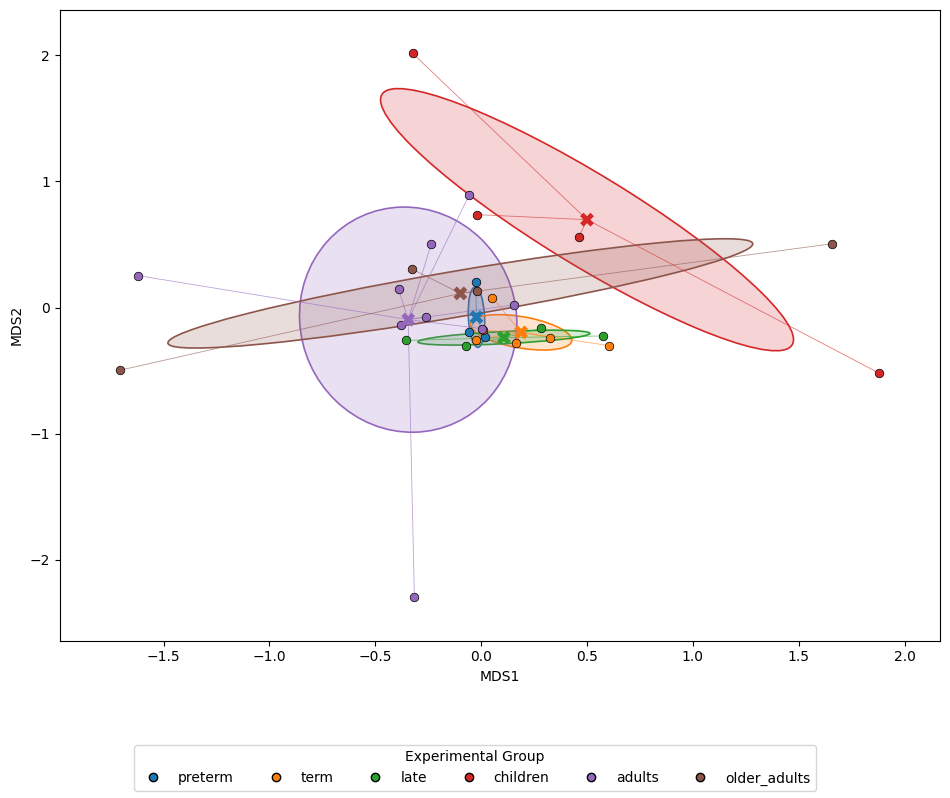

In [54]:
# Рисуем две координаты MDS с цветом групп, центрами и разбросом.
rsplot.beta_mds(ucb_cd4_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

**Кластеризация похожих CDR3.** Здесь **объекты — последовательности клонотипов**, а не образцы. Если две последовательности удовлетворяют правилу сходства, между ними можно провести ребро графа. `overlap_type='aaV'` использует аминокислотные CDR3 и V-ген, `mismatches=1` допускает одно несовпадение между сравниваемыми последовательностями.

Важная деталь: в связанном кластере две далёкие вершины могут отличаться **более чем на один символ**, поскольку соединяются цепочкой промежуточных вариантов. Такие кластеры — кандидаты для последующего поиска общей специфичности, но не прямое доказательство распознавания одного антигена. Расчёт и отрисовка могут быть тяжёлыми на больших данных.

## Clustering

### Create clusters

In [55]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [56]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets_cd4, cl_filter=downsample_filter)

Pooled 154304 clonotypes from 30 samples


In [57]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 154304 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 718/718 tasks processed
found 70049 edges
-----------------------------
NexworkX graph created
Found 8032 clusters (2 or more nodes) and 116699 single nodes. Total: 124731


In [58]:
# Добавляем к вершинам/последовательностям метаданные экспериментальных групп.
clusters.add_metadata(metadata)

In [59]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,4813,CASVRDRGTEAFF,TRBV5-1,TRBJ1-1,TGCGCCAGCGTCCGGGACAGGGGCACTGAAGCTTTCTTT,c1_mnCD4_TRB_1,0.000364,2,None,1,children,c1,nCD4,PB
1,0,114032,CASSLARGTEAFF,TRBV5-1,TRBJ1-1,TGCGCCAGCAGCTTGGCCAGGGGCACTGAAGCTTTCTTT,UCB5_nCD4_TRB_2,0.000182,1,None,9,preterm,UCB5,nCD4,UCB
2,0,13884,CASSSGGTGELFF,TRBV5-1,TRBJ2-2,TGCGCCAGCAGCTCCGGTGGAACCGGGGAGCTGTTTTTT,a13_mnCD4_TRB_1,0.000182,1,None,5,adults,a13,nCD4,PB
3,0,13742,CASGLAGTYEQYF,TRBV5-1,TRBJ2-7,TGCGCCAGCGGACTAGCGGGAACCTACGAGCAGTACTTC,a13_mnCD4_TRB_1,0.000182,1,None,1,adults,a13,nCD4,PB
4,0,66628,CASSLDSRETQYF,TRBV5-1,TRBJ2-5,TGCGCCAGCAGCCTCGATTCTAGGGAGACCCAGTACTTC,c5_mnCD4_TRB_1,0.000182,1,None,1,children,c5,nCD4,PB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154299,124726,43527,YEAGECCSYNEQFF,TRBV20-1,TRBJ2-1,TACGAAGCGGGAGAGTGCTGTTCCTACAATGAGCAGTTCTTC,a1_mnCD4_TRB_1,0.000182,1,None,0,adults,a1,nCD4,PB
154300,124727,19012,YSATQTNTEAFF,TRBV20-1,TRBJ1-1,TACAGTGCTACACAAACGAACACTGAAGCTTTCTTT,o6_mnCD4_TRB_2,0.000182,1,None,0,older_adults,o6,nCD4,PB
154301,124728,38963,YSGRDPYYNEQFF,TRBV21-1,TRBJ2-1,TATTCAGGCCGGGACCCTTATTACAATGAGCAGTTCTTC,a15_mnCD4_TRB_1,0.000182,1,None,0,adults,a15,nCD4,PB
154302,124729,77528,YSSAGGTDTQYF,TRBV17,TRBJ2-3,TACAGTAGCGCCGGAGGCACAGATACGCAGTATTTT,UCB9_nCD4_TRB_2,0.000182,1,None,0,late,UCB9,nCD4,UCB


In [60]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |#########-----------------------------------------| 23996/124731 clusters processed

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Calculating cluster properties |########################--------------------------| 61576/124731 clusters processed

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Calculating cluster properties |#######################################-----------| 99195/124731 clusters processed

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



Calculating cluster properties |##################################################| 124731/124731 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,1285,6201,1417,27,0.007517,20.682490,CASSLGGTTEQYF,TGCGCCAGCAGCTTGGGGGGGACCGATGAGCAGTACTTT,TRBV5-1,TRBJ1-1
1,1,cluster_1,1049,3951,1156,32,0.007188,23.662536,CASSLGGGTDEQYF,TGCGCCAGCAGCTTGGGGGGGGGCACAGATGAGCAGTACTTC,TRBV5-1,TRBJ2-3
2,2,cluster_2,637,3276,694,19,0.016173,13.734694,CASSLGGDEQYF,TGCGCCAGCAGCTTGGGCGGCGATGAGCAGTACTTT,TRBV5-1,TRBJ2-3
3,3,cluster_3,407,1944,459,12,0.023529,8.560197,CASSLGGGNTEAFF,TGCGCCAGCAGCTTGGGGGGGGGGAACACTGAAGCTTTCTTT,TRBV5-1,TRBJ1-1
4,4,cluster_4,385,1310,420,14,0.017722,10.677922,CASSLGGGSYNEQFF,TGCGCCAGCAGCTTGGGAGGGGGGGCCTACAATGAGCAGTTCTTC,TRBV5-1,TRBJ2-1
...,...,...,...,...,...,...,...,...,...,...,...,...
124726,124726,cluster_124726,1,0,1,0,0.000000,0.000000,YEAGECCSYNEQFF,TACGAAGCGGGAGAGTGCTGTTCCTACAATGAGCAGTTCTTC,TRBV20-1,TRBJ2-1
124727,124727,cluster_124727,1,0,1,0,0.000000,0.000000,YSATQTNTEAFF,TACAGTGCTACACAAACGAACACTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1
124728,124728,cluster_124728,1,0,1,0,0.000000,0.000000,YSGRDPYYNEQFF,TATTCAGGCCGGGACCCTTATTACAATGAGCAGTTCTTC,TRBV21-1,TRBJ2-1
124729,124729,cluster_124729,1,0,1,0,0.000000,0.000000,YSSAGGTDTQYF,TACAGTAGCGCCGGAGGCACAGATACGCAGTATTTT,TRBV17,TRBJ2-3


In [61]:
# Отбираем кластеры, исключая указанные V- и J-сегменты из демонстрации.
# # Поля concensus_v/concensus_j названы так в выводе библиотеки.
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
9,9,cluster_9,235,744,256,15,0.027059,11.370213,CSARGGTETQYF,TGCAGTGCTAGAGGGGGCACAGAGACCCAGTACTTC,TRBV20-1,TRBJ2-5
12,12,cluster_12,208,955,234,14,0.044361,9.312500,CASSLGGNTEAFF,TGTGCCAGCAGTTTAGGGGGGAACACTGAAGCTTTCTTT,TRBV12-3,TRBJ1-1
16,16,cluster_16,172,877,194,16,0.059636,11.500000,CASSLGGNQPQHF,TGTGCCAGCAGTTTAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
21,21,cluster_21,132,280,142,18,0.032385,13.840909,CSARGGGNQPQHF,TGCAGTGCTAGAGGGGGGGGCAATCAGCCCCAGCATTTT,TRBV20-1,TRBJ1-5
27,27,cluster_27,118,412,136,19,0.059684,14.466102,CASSLGGGNQPQHF,TGTGCCAGCAGTTTAGGAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
...,...,...,...,...,...,...,...,...,...,...,...,...
124723,124723,cluster_124723,1,0,1,0,0.000000,0.000000,YASSLWEKEKLFF,TATGCCAGCAGCTTATGGGAGAAAGAAAAACTGTTTTTT,TRBV7-2,TRBJ1-4
124724,124724,cluster_124724,1,0,1,0,0.000000,0.000000,YASSRQGFYQETQYF,TATGCCAGCAGCCGCCAGGGGTTCTACCAAGAGACCCAGTACTTC,TRBV12-3,TRBJ2-5
124726,124726,cluster_124726,1,0,1,0,0.000000,0.000000,YEAGECCSYNEQFF,TACGAAGCGGGAGAGTGCTGTTCCTACAATGAGCAGTTCTTC,TRBV20-1,TRBJ2-1
124727,124727,cluster_124727,1,0,1,0,0.000000,0.000000,YSATQTNTEAFF,TACAGTGCTACACAAACGAACACTGAAGCTTTCTTT,TRBV20-1,TRBJ1-1


In [62]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 154304
    samples: 30
    input_samples: 30
    filter:
      name: default_filter
      functionality: f
      downsample_size: 5500
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 154304 nodes and 70049 edges
Clusters: 8032 clusters (2 or more nodes) and 116699 single nodes. Total: 124731
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: experimental_group, donor_id, subset, source
Node Pgen: not calculated
ALICE: not calculated

**Визуализация графа.** Вершины представляют последовательности/клонотипы, ребра — заданное выше сходство. Цвет показывает экспериментальную группу; подписи и размеры связаны с числом наблюдений. Здесь выводятся кластеры с номерами от 20 до 29; сами номера — **идентификаторы по результату текущего расчёта**, а не универсальные биологические метки. При другом входном наборе или параметрах их состав может измениться.

### Plot clusters

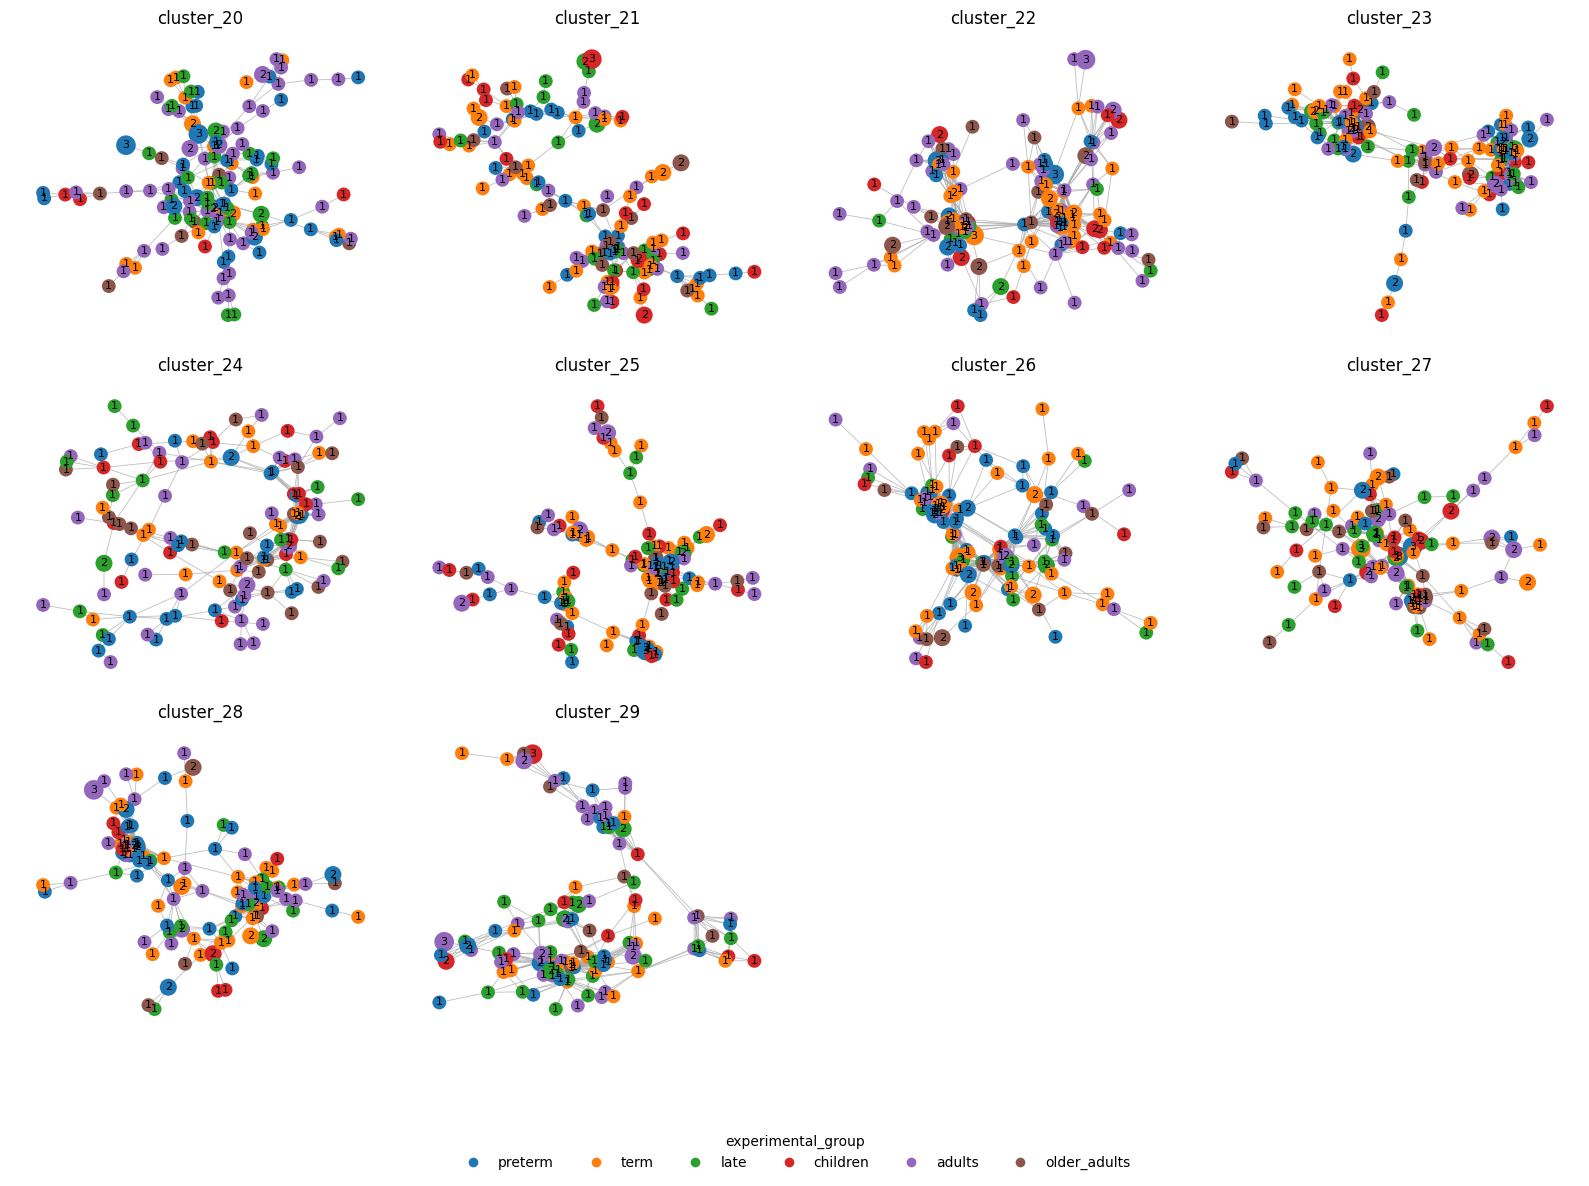

In [63]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)

## Проверка устойчивости: downsample 5500 против 12 000

Повторяем расчёт альфа-разнообразия на большей глубине (12 000). Образец `c2_mnCD4_TRB_1` до этой глубины не дотягивает, поэтому исключаем его явно. Смотрим, сохраняется ли порядок групп по основным метрикам.

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

clonosets_cd4_deep = clonosets_cd4.merge(
    clonoset_stats_cd4[["sample_id", "reads_func"]], on="sample_id"
).query("reads_func >= @DOWNSAMPLE_CHECK").drop(columns="reads_func").reset_index(drop=True)
print("Образцов при глубине", DOWNSAMPLE_CHECK, ":", len(clonosets_cd4_deep))

check_filter = clf.Filter(functionality="f", downsample=DOWNSAMPLE_CHECK, by_umi=True, seed=100)
diversity_check = stats.calc_diversity_stats(clonosets_cd4_deep, cl_filter=check_filter, seed=123,
                                             cpu=2, iterations=3, drop_small_samples=False, verbose=True)

Образцов при глубине 12000 : 29
CalcDiversityStats settings: seed=123, downsample=12000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 29/29 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_mnCD4_TRB_2, o5_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a11_mnCD4_TRB_1, UCB2_nCD4_TRB_1, UCB4_nCD4_TRB_1, c1_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB3_nCD4_TRB_1, a5_mnCD4_TRB_1, a10_mnCD4_TRB_1, a3_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB11_nCD4_TRB_1, UCB13_mnCD4_TRB_1, a13_mnCD4_TRB_1, UCB7_nCD4_TRB_1, a15_mnCD4_TRB_1, o1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, o6_mnCD4_TRB_2, c5_mnCD4_TRB_1, UCB10_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB12_mnCD4_TRB_1, a7_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB6_nCD4_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 2

In [65]:
# Усредняем повторы субсэмплирования внутри образца и сравниваем медианы групп.
metrics_to_compare = [m for m in ["diversity", "shannon_wiener", "norm_shannon_wiener", "clonality"]
                      if m in diversity_stats.columns]

def per_sample(df, depth):
    out = df.groupby("sample_id")[metrics_to_compare].mean().reset_index()
    out["downsample"] = depth
    return out

depth_comparison = pd.concat([per_sample(diversity_stats, DOWNSAMPLE),
                              per_sample(diversity_check, DOWNSAMPLE_CHECK)]).merge(metadata, on="sample_id")

depth_comparison.groupby(["experimental_group", "downsample"], observed=True)[metrics_to_compare].median().unstack().round(4)

diversity          shannon_wiener          \
downsample             5500     12000          5500    12000   
experimental_group                                             
preterm               5181.0  10650.0         8.5286  9.2246   
term                  5284.0  11044.0         8.5570  9.2779   
late                  5230.5  10785.5         8.5437  9.2477   
children              4955.5  10976.0         8.4669  9.2700   
adults                5176.0  10503.0         8.5292  9.2113   
older_adults          5335.5  11181.5         8.5703  9.2946   

                   norm_shannon_wiener         clonality          
downsample                       5500    12000     5500    12000  
experimental_group                                                
preterm                         0.9972  0.9947    0.0028  0.0053  
term                            0.9982  0.9966    0.0018  0.0034  
late                            0.9978  0.9959    0.0022  0.0041  
children                        0.9953  0.9964    0.0047  0.0036  
adults                          0.9974  0.9948    0.0026  0.0052  
older_adults                    0.9986  0.9971    0.0014  0.0029

In [66]:
# Ранги групп по медиане: совпадает ли порядок при двух глубинах?
medians = depth_comparison.groupby(["downsample", "experimental_group"], observed=True)[metrics_to_compare].median()
medians.groupby(level="downsample").rank(ascending=False).unstack(level="downsample")

diversity       shannon_wiener       norm_shannon_wiener  \
downsample             5500  12000          5500  12000               5500    
experimental_group                                                            
preterm                  4.0   5.0            5.0   5.0                 5.0   
term                     2.0   2.0            2.0   2.0                 2.0   
late                     3.0   4.0            3.0   4.0                 3.0   
children                 6.0   3.0            6.0   3.0                 6.0   
adults                   5.0   6.0            4.0   6.0                 4.0   
older_adults             1.0   1.0            1.0   1.0                 1.0   

                         clonality        
downsample         12000     5500  12000  
experimental_group                        
preterm              6.0       2.0   1.0  
term                 2.0       5.0   5.0  
late                 4.0       4.0   3.0  
children             3.0       1.0   4.0  
adults               5.0       3.0   2.0  
older_adults         1.0       6.0   6.0

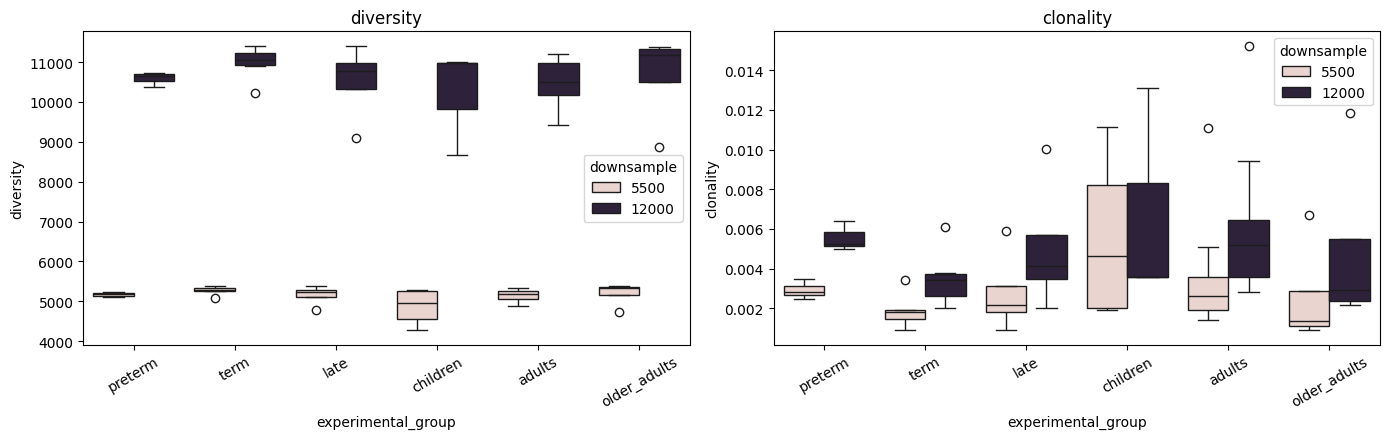

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["diversity", "clonality"]):
    sns.boxplot(data=depth_comparison, x="experimental_group", y=metric, hue="downsample", ax=ax)
    ax.tick_params(axis="x", rotation=30)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

## Выводы

**Коротко.** Сравнивали 6 возрастных групп в популяции наивных CD4 T-клеток: 3 группы пуповинной крови (preterm, term, late) и 3 группы периферической крови (children, adults, older_adults).
- У preterm CDR3 короче, вставок в 2 раза меньше, почти четверть CDR3 без вставок и выше convergence, это самый четкий результат (скорее всего слабая работа TdT у плода).
- V и J сегменты почти не отличаются между группами, есть только слабые тренды с возрастом (TRBV29-1, TRBJ2-1 и TRBJ2-5 растут, TRBJ1-2 снижается).
- Все репертуары очень разнообразные, различия между группами около 5% и при изменении глубины частично меняются, устойчиво только то, что older_adults самые разнообразные.
- У preterm намного больше общих клонотипов между разными детьми (F2 внутри группы в 10-60 раз выше), особенно у самых недоношенных (24 и 25 недель).
- Главное ограничение: UCB и периферическая кровь отсортированы по разным схемам, а в группах всего 3-9 образцов.

**Как читать графики.** На boxplot'ах (свойства CDR3, convergence, разнообразие) по оси X экспериментальные группы, по оси Y значение метрики, одна точка это один образец, линия в ящике это медиана. На распределении длин CDR3 по X длина в аминокислотах, по Y доля клонотипов такой длины. На V/J usage по X сегмент, по Y его доля в репертуаре. На rarefaction по X число наблюдений в подвыборке, по Y сколько разных клонотипов при этом найдено, если кривая выходит на плато значит образец почти насыщен. На тепловой карте F2 каждая клетка это пара образцов, чем краснее тем больше общих клонотипов с учетом их частот. На MDS оси MDS1 и MDS2 условные, у них нет биологического смысла, важно только расстояние: чем ближе точки, тем похожее репертуары. На графе кластеров вершина это клонотип, ребро соединяет клонотипы с одинаковым V и CDR3, отличающимися на 1 аминокислоту.

### Подробно

**Выборка.** В анализ вошли все 30 образцов nCD4: preterm 3, term 6, late 4, children 4, adults 9, older_adults 4. Глубина образцов отличалась больше чем в 40 раз (от 5912 до 254528 функциональных наблюдений), поэтому взяли downsample 5500, при нем ни один образец не выпадает. Важный момент - все образцы из периферической крови и 2 образца term отсортированы строже (mnCD4: CD25-, CD45RA+, CD27+, CD31-), а остальные образцы UCB отобраны только как CD3+CD4+. То есть сравнение UCB и периферической крови частично совпадает с разницей в сортировке.

**CDR3.** Самый четкий результат. У preterm CDR3 короче (медиана 40,8 нт против 42,5-42,7 у term и late и 43,1-43,7 у детей и взрослых), вставок примерно в 2 раза меньше (3,5 нт против 6,2-7,5), а почти четверть CDR3 (23,6%) вообще без вставок, у остальных групп таких 2-5%. На распределении длин у preterm пик на 13-14 аминокислотах, у late на 14-15. Скорее всего это связано с тем, что у плода на ранних сроках TdT работает слабо и добавляет меньше случайных нуклеотидов.

**V и J сегменты.** Во всех группах лидирует TRBV5-1 (медиана 13,5%), дальше TRBV20-1 (9,0%) и TRBV12-3 (8,9%). Сильных различий между группами нет, есть только мягкие тренды: TRBV29-1 растет с возрастом (с 2,3% у preterm до 5,5% у older_adults), TRBV12-3 наоборот немного снижается (с 9,3% до 7,5%). Среди J чаще всего TRBJ2-1 (15,7%), TRBJ2-7 (15,3%) и TRBJ2-3 (13,0%). С возрастом растут доли TRBJ2-1 (с 13,0% у preterm до 17,4% у older_adults) и TRBJ2-5 (с 7,1% до 11,2%), а TRBJ1-2 снижается (с 10,8% до 7,8%).

**Convergence.** Выше всего у preterm (медиана 1,052), у term и late около 1,006, у детей и взрослых около 1,003. С учетом V гена значения ближе к 1, но preterm все равно выше (1,010). Это логично связано с CDR3: если вставок мало, последовательности ближе к зародышевым, и одна и та же аминокислотная CDR3 чаще получается из разных нуклеотидных.

**Альфа-разнообразие.** Все репертуары очень разнообразные, как и должно быть для наивных клеток: из 5500 наблюдений 4950-5340 это разные клонотипы, нормированный Шеннон больше 0,995, clonality 0,001-0,005. Медиана diversity максимальная у older_adults (5336) и минимальная у children (4956), но минимум у children в основном дает один образец c2 (4268), самый маленький по глубине. У взрослого a9 есть заметный клон (1,2% репертуара), для наивных клеток это необычно, возможно это примесь клеток памяти. Goods coverage всего 6-18%, и rarefaction кривые продолжают расти, то есть до насыщения далеко.

**Проверка устойчивости.** Пересчитали разнообразие при downsample 12000 (c2 при этом выпадает). Older_adults остаются на первом месте, term на втором, а вот остальные группы меняются местами: children поднимаются с последнего места на третье, preterm и adults опускаются вниз. Значит различия по разнообразию между группами маленькие (около 5%) и зависят от глубины и состава выборки, кроме лидерства older_adults делать выводы по ним нельзя.

**Бета-разнообразие.** Сходство между людьми в целом очень низкое, медиана F2 по всем парам 0,0012. Средний F2 внутри preterm 0,029, это в 10 раз больше, чем внутри term (0,003) и late (0,002), и в 30-60 раз больше, чем внутри групп периферической крови (0,0005-0,0009). Самая похожая пара это UCB1 и UCB5 (F2 = 0,051), за ними идут пары с третьим preterm UCB11 (около 0,019). Проверили родство: UCB1 и UCB5 не из одной семьи, зато это два самых недоношенных ребенка (25 и 24 недели), UCB11 родился на 29 неделе. Получается, чем раньше срок, тем больше общих клонотипов, скорее всего из-за коротких CDR3 без вставок, которые чаще совпадают у разных людей (публичные клонотипы). При кластеризации тепловая карта разделяет образцы UCB и периферической крови. На MDS образцы UCB лежат компактно в центре, а дети и пожилые разбросаны сильнее, четкого разделения групп нет.

**Кластеры.** Самые большие кластеры (сотни и тысячи последовательностей) все на TRBV5-1 с мотивами CASSLGG..., то есть это скорее отражение самого частого V гена и зародышевых последовательностей, а не общей специфичности.

**Сравнение с nTreg.** Числа для nTreg взяты из семинарского ноутбука UCB_seminar.ipynb (там downsample 4500, поэтому разнообразие сравниваю только по направлению изменений). По CDR3 и convergence результаты почти такие же, как у Treg (у preterm тоже 40,7 нт, 3,3 вставки и convergence 1,053), значит эти особенности связаны с возрастом и работой TdT, а не с конкретной популяцией. А вот разнообразие ведет себя по-другому: у Treg с возрастом оно падает и clonality растет (максимум у older_adults 0,011), а у наивных CD4 older_adults наоборот самые разнообразные. Возможно Treg больше делятся на периферии и образуют экспансии, но на nCD4 могла повлиять и более строгая сортировка (CD31-).

**Ограничения.** В группах мало образцов (3-9), статистика не проверялась, все различия описательные. Даунсэмплинг случайный, хотя seed фиксирован. Сравнение UCB и периферической крови смешано с разной схемой сортировки. Колонки UMI в данных пустые, поэтому считали по reads.